In [1]:
# Cell 1: Find the Week 3 benchmark files

import os

for root, dirs, files in os.walk("/content"):
    if "manifest.csv" in files:
        print("Found manifest:", os.path.join(root, "manifest.csv"))

    if "splits.csv" in files:
        print("Found splits:", os.path.join(root, "splits.csv"))

    if "label_taxonomy.csv" in files:
        print("Found taxonomy:", os.path.join(root, "label_taxonomy.csv"))


In [2]:
# Cell 2: Check what files are currently in Colab

import os

print("Files in /content:")
print(os.listdir("/content"))

Files in /content:
['.config', 'sample_data']


In [3]:
# Cell 3: Download your GitHub repository into Colab

!git clone https://github.com/cecezhuo/ingen_vlm_bench_v1.0.git


Cloning into 'ingen_vlm_bench_v1.0'...
remote: Enumerating objects: 227, done.
remote: Total 227 (delta 0), reused 0 (delta 0), pack-reused 227 (from 1)
Receiving objects: 100% (227/227), 21.02 MiB | 23.29 MiB/s, done.
Resolving deltas: 100% (96/96), done.


In [4]:
# Cell 4: Check the files in your repository

import os

repo_path = "/content/ingen_vlm_bench_v1.0"

print("Repository folders and files:")
print(os.listdir(repo_path))


Repository folders and files:
['weekly', 'src', 'tests', 'README.md', 'deliverables', '.git', 'data', 'configs', 'results', 'notebooks']


In [5]:
# Cell 5: List the files in the data folder

data_path = os.path.join(repo_path, "data")

print("Files in data folder:")
print(os.listdir(data_path))


Files in data folder:
['W03_Benchmark_Construction.ipynb', 'split_summary.csv', 'W03_Label_Audit.md', 'open_images_class_matches.csv', 'test_split_sha256.txt', 'label_taxonomy.csv', 'manifest.csv']


In [6]:
# Cell 6: Load and inspect the benchmark manifest

import pandas as pd

manifest_path = os.path.join(data_path, "manifest.csv")

manifest = pd.read_csv(manifest_path)

print("Number of rows:", len(manifest))
print("\nColumn names:")
print(manifest.columns.tolist())

print("\nFirst 5 rows:")
display(manifest.head())


Number of rows: 566

Column names:
['image_id', 'image_path', 'source', 'license', 'author', 'source_url', 'class_ids', 'english_labels', 'open_images_split', 'lighting', 'clutter', 'viewpoint', 'benchmark_split']

First 5 rows:


,image_id,image_path,source,license,author,source_url,class_ids,english_labels,open_images_split,lighting,clutter,viewpoint,benchmark_split
0,0035a4bfeda1b637,data/images/open_images/0035a4bfeda1b637.jpg,Open Images,https://creativecommons.org/licenses/by/2.0/,A M,https://www.flickr.com/photos/anonymousmxpt/82...,K04;K07,Bowl;Spoon,validation,unknown,unknown,unknown,validation
1,003775320f1d6937,data/images/open_images/003775320f1d6937.jpg,Open Images,https://creativecommons.org/licenses/by/2.0/,wemissedthebus,https://www.flickr.com/photos/24936303@N08/702...,F04,Table,validation,unknown,unknown,unknown,test
2,00794645d77184eb,data/images/open_images/00794645d77184eb.jpg,Open Images,https://creativecommons.org/licenses/by/2.0/,Steven Pisano,https://www.flickr.com/photos/stevenpisano/152...,F06,Door,validation,unknown,unknown,unknown,validation
3,00a36f96e31731c4,data/images/open_images/00a36f96e31731c4.jpg,Open Images,https://creativecommons.org/licenses/by/2.0/,Johan Larsson,https://www.flickr.com/photos/johanl/8289365270,F05,Desk,validation,unknown,unknown,unknown,validation
4,00eb69293aa4c5b7,data/images/open_images/00eb69293aa4c5b7.jpg,Open Images,https://creativecommons.org/licenses/by/2.0/,FaceMePLS,https://www.flickr.com/photos/faceme/6594671309,P02,Glasses,validation,unknown,unknown,unknown,test


In [7]:
# Cell 7: Check benchmark splits and image paths

from pathlib import Path

print("Images in each benchmark split:")
print(manifest["benchmark_split"].value_counts())

print("\nImages in each Open Images split:")
print(manifest["open_images_split"].value_counts())

# Check whether the image files exist
manifest["full_image_path"] = manifest["image_path"].apply(
    lambda path: os.path.join(repo_path, path)
)

manifest["image_exists"] = manifest["full_image_path"].apply(
    lambda path: os.path.exists(path)
)

print("\nImages found:", manifest["image_exists"].sum())
print("Images missing:", (~manifest["image_exists"]).sum())

print("\nMissing image examples:")
display(
    manifest.loc[~manifest["image_exists"], ["image_id", "image_path"]].head()
)


Images in each benchmark split:
benchmark_split
validation    260
test          257
adaptation     49
Name: count, dtype: int64

Images in each Open Images split:
open_images_split
validation    517
train          49
Name: count, dtype: int64

Images found: 0
Images missing: 566

Missing image examples:


,image_id,image_path
0,0035a4bfeda1b637,data/images/open_images/0035a4bfeda1b637.jpg
1,003775320f1d6937,data/images/open_images/003775320f1d6937.jpg
2,00794645d77184eb,data/images/open_images/00794645d77184eb.jpg
3,00a36f96e31731c4,data/images/open_images/00a36f96e31731c4.jpg
4,00eb69293aa4c5b7,data/images/open_images/00eb69293aa4c5b7.jpg


In [8]:
# Cell 8: Check the image folders in the repository

image_folder = os.path.join(repo_path, "data", "images")

print("Does the images folder exist?")
print(os.path.exists(image_folder))

if os.path.exists(image_folder):
    print("\nContents of images folder:")
    print(os.listdir(image_folder))
else:
    print("\nNo images folder found.")

print("\nChecking Git ignore rules:")
!cd /content/ingen_vlm_bench_v1.0 && git status --short


Does the images folder exist?
False

No images folder found.

Checking Git ignore rules:


In [9]:
# Cell 9: Find the image download code from Week 3

import json

notebook_path = os.path.join(
    repo_path,
    "data",
    "W03_Benchmark_Construction.ipynb"
)

with open(notebook_path, "r") as f:
    week3_notebook = json.load(f)

for i, cell in enumerate(week3_notebook["cells"]):
    if cell["cell_type"] == "code":
        code = "".join(cell["source"])

        if any(word in code.lower() for word in [
            "download", "image", "requests", "wget", "open_images"
        ]):
            print(f"\n--- Week 3 Cell {i} ---")
            print(code[:2000])



--- Week 3 Cell 7 ---
# Cell 7: Download the corrected taxonomy

from google.colab import files

files.download("label_taxonomy.csv")

--- Week 3 Cell 9 ---
# Cell 9: Create the dataset manifest template

import os
import pandas as pd

# Create the data folder if it does not already exist
os.makedirs("data", exist_ok=True)

# Define the columns for our dataset manifest
manifest_columns = [
    "image_id",
    "image_path",
    "source",
    "source_image_id",
    "license",
    "author",
    "class_id",
    "lighting",
    "clutter",
    "viewpoint",
    "split",
    "notes"
]

# Create an empty manifest with these columns
manifest_df = pd.DataFrame(columns=manifest_columns)

# Save the empty manifest
manifest_df.to_csv(
    "data/manifest.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Manifest template created successfully!")
print("\nColumns:")
print(manifest_df.columns.tolist())

print("\nNumber of image records:", len(manifest_df))

--- Week 3 Cell 10 ---
# Cell 10: Def

In [ ]:
# Cell 10: Check common locations for the Week 3 images

import os

folders_to_check = [
    "/content/data/images/open_images",
    "/content/ingen_vlm_bench_v1.0/data/images/open_images",
    "/root/fiftyone"
]

for folder in folders_to_check:
    print("\nFolder:", folder)
    if os.path.exists(folder):
        print("Found!")
        print("Contents:", os.listdir(folder)[:10])
    else:
        print("Not found")


Folder: /content/data/images/open_images
Not found

Folder: /content/ingen_vlm_bench_v1.0/data/images/open_images
Not found

Folder: /root/fiftyone
Not found


In [ ]:
# Cell 11: Check image IDs and source URLs
print(manifest[["image_id", "image_path", "source_url"]].head(10).to_string(index=False))

        image_id                                   image_path                                               source_url
0035a4bfeda1b637 data/images/open_images/0035a4bfeda1b637.jpg   https://www.flickr.com/photos/anonymousmxpt/8266725786
003775320f1d6937 data/images/open_images/003775320f1d6937.jpg    https://www.flickr.com/photos/24936303@N08/7026265947
00794645d77184eb data/images/open_images/00794645d77184eb.jpg   https://www.flickr.com/photos/stevenpisano/15256561208
00a36f96e31731c4 data/images/open_images/00a36f96e31731c4.jpg          https://www.flickr.com/photos/johanl/8289365270
00eb69293aa4c5b7 data/images/open_images/00eb69293aa4c5b7.jpg          https://www.flickr.com/photos/faceme/6594671309
00f3dbbbf5bdf2cf data/images/open_images/00f3dbbbf5bdf2cf.jpg       https://www.flickr.com/photos/wuzzlive/15557668485
02bc8361b1beb582 data/images/open_images/02bc8361b1beb582.jpg https://www.flickr.com/photos/audiolucistore/11047098446
02d3d8579d152a67 data/images/open_images/02d3d85

In [ ]:
# Cell 12: Test a few exact Open Images image IDs
import os
import requests

image_folder = os.path.join(repo_path, "data", "images", "open_images")
os.makedirs(image_folder, exist_ok=True)

for _, row in manifest.head(3).iterrows():
    image_id = row["image_id"]
    split = row["open_images_split"]

    url = f"https://storage.googleapis.com/openimages/2018_04/{split}/{image_id}.jpg"
    response = requests.get(url, timeout=30)

    print(image_id, split, response.status_code, response.headers.get("Content-Type"))

    if response.status_code == 200 and "image" in response.headers.get("Content-Type", ""):
        save_path = os.path.join(image_folder, f"{image_id}.jpg")
        with open(save_path, "wb") as f:
            f.write(response.content)
        print("Saved:", save_path)

0035a4bfeda1b637 validation 403 application/xml; charset=UTF-8
003775320f1d6937 validation 403 application/xml; charset=UTF-8
00794645d77184eb validation 403 application/xml; charset=UTF-8


In [10]:
# Cell 13: Download the exact images from our manifest
!pip install -q fiftyone

import os
import shutil
from pathlib import Path
import fiftyone as fo
import fiftyone.zoo as foz

image_folder = os.path.join(repo_path, "data", "images", "open_images")
os.makedirs(image_folder, exist_ok=True)

for split in manifest["open_images_split"].unique():

    image_ids = manifest.loc[
        manifest["open_images_split"] == split, "image_id"
    ].astype(str).tolist()

    dataset_name = f"w04_recovery_{split}"

    if fo.dataset_exists(dataset_name):
        fo.delete_dataset(dataset_name)

    print(f"Downloading {len(image_ids)} images from {split}...")

    dataset = foz.load_zoo_dataset(
        "open-images-v7",
        split=split,
        label_types=["detections"],
        image_ids=image_ids,
        dataset_name=dataset_name
    )

    for sample in dataset:
        image_id = Path(sample.filepath).stem
        destination = os.path.join(image_folder, f"{image_id}.jpg")
        shutil.copy2(sample.filepath, destination)

    print(f"Finished {split}")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


/usr/local/lib/python3.13/dist-packages/glob2/fnmatch.py:141: SyntaxWarning: invalid escape sequence '\Z'
  return '(?ms)' + res + '\Z'


INFO:fiftyone.zoo.datasets:Downloading split 'validation' to '/root/fiftyone/open-images-v7/validation' if necessary


INFO:fiftyone.utils.openimages:Downloading 'https://storage.googleapis.com/openimages/2018_04/validation/validation-images-with-rotation.csv' to '/root/fiftyone/open-images-v7/validation/metadata/image_ids.csv'


INFO:fiftyone.utils.openimages:Downloading 'https://storage.googleapis.com/openimages/v5/class-descriptions-boxable.csv' to '/root/fiftyone/open-images-v7/validation/metadata/classes.csv'


INFO:fiftyone.utils.openimages:Downloading 'https://storage.googleapis.com/openimages/2018_04/bbox_labels_600_hierarchy.json' to '/tmp/tmp51vm9k_4/metadata/hierarchy.json'


... (28 outputs left out)

INFO:eta.core.utils: 100% |███████████████████| 49/49 [235.8ms elapsed, 0s remaining, 212.1 samples/s] 


Dataset 'w04_recovery_train' created


INFO:fiftyone.zoo.datasets:Dataset 'w04_recovery_train' created


Finished train


In [11]:
# Cell 14: Count the recovered images
found_images = [
    image_id for image_id in manifest["image_id"]
    if os.path.exists(os.path.join(image_folder, f"{image_id}.jpg"))
]

print("Images recovered:", len(found_images), "out of", len(manifest))

Images recovered: 566 out of 566


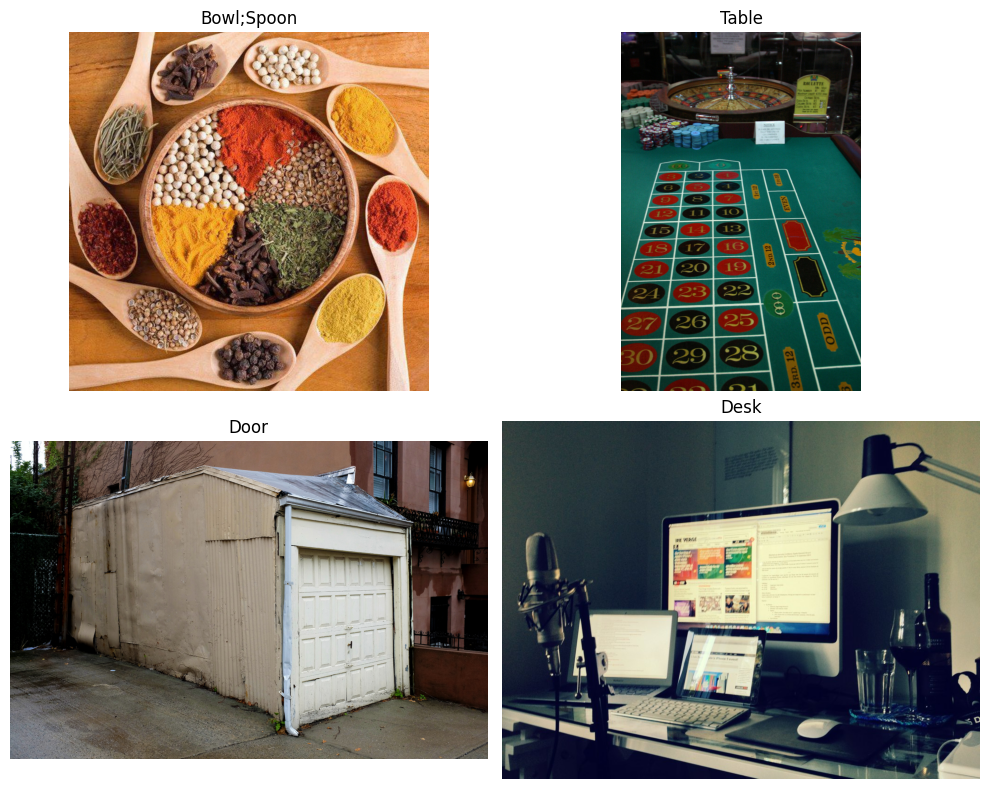

In [12]:
# Cell 15: View a few recovered benchmark images
from PIL import Image
import matplotlib.pyplot as plt

sample_images = manifest.head(4)

plt.figure(figsize=(10, 8))

for i, (_, row) in enumerate(sample_images.iterrows()):
    image_path = os.path.join(repo_path, row["image_path"])
    img = Image.open(image_path).convert("RGB")

    plt.subplot(2, 2, i + 1)
    plt.imshow(img)
    plt.title(row["english_labels"])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [13]:
# Cell 16: Install libraries for Week 4 models
!pip install -q open_clip_torch transformers accelerate scikit-learn

In [14]:
# Cell 17: Check GPU and import model libraries
import torch
import open_clip
import transformers
import sklearn

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("OpenCLIP:", open_clip.__version__)
print("Transformers:", transformers.__version__)
print("Libraries loaded successfully!")

PyTorch version: 2.14.1+cu130
GPU available: True
GPU: Tesla T4
OpenCLIP: 4.2.2
Transformers: 5.22.1
Libraries loaded successfully!


In [15]:
# Cell 18: Load the OpenCLIP model
import open_clip

model_name = "ViT-B-32"
pretrained = "laion2b_s34b_b79k"

model, _, preprocess = open_clip.create_model_and_transforms(
    model_name,
    pretrained=pretrained,
    device="cuda"
)

tokenizer = open_clip.get_tokenizer(model_name)

model.eval()

print("OpenCLIP loaded successfully!")

open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

OpenCLIP loaded successfully!


In [16]:
# Cell 19: Test OpenCLIP with one benchmark image
from PIL import Image
import torch
import os

row = manifest.iloc[0]
image_path = os.path.join(repo_path, row["image_path"])

image = preprocess(Image.open(image_path).convert("RGB"))
image = image.unsqueeze(0).to("cuda")

labels = ["Mug", "Book", "Backpack", "Headphones"]
text = tokenizer([f"a photo of a {label}" for label in labels]).to("cuda")

with torch.no_grad():
    image_features = model.encode_image(image)
    text_features = model.encode_text(text)

    image_features = image_features / image_features.norm(dim=-1, keepdim=True)
    text_features = text_features / text_features.norm(dim=-1, keepdim=True)

    scores = (image_features @ text_features.T).squeeze(0)

for label, score in zip(labels, scores):
    print(f"{label}: {score.item():.4f}")

print("Predicted label:", labels[scores.argmax().item()])

Mug: 0.1430
Book: 0.1154
Backpack: 0.1217
Headphones: 0.1125
Predicted label: Mug


In [17]:
# Cell 20: Create a function to predict an image's label
def predict_openclip(image_path, labels, prompt="a photo of a {}"):
    image = preprocess(Image.open(image_path).convert("RGB"))
    image = image.unsqueeze(0).to("cuda")

    text = tokenizer([prompt.format(label) for label in labels]).to("cuda")

    with torch.no_grad():
        image_features = model.encode_image(image)
        text_features = model.encode_text(text)

        image_features = image_features / image_features.norm(dim=-1, keepdim=True)
        text_features = text_features / text_features.norm(dim=-1, keepdim=True)

        scores = (image_features @ text_features.T).squeeze(0)

    best_index = scores.argmax().item()
    return labels[best_index], scores.cpu().numpy()

In [18]:
# Test the prediction function
prediction, scores = predict_openclip(
    image_path,
    ["Mug", "Book", "Backpack", "Headphones"]
)

print("Prediction:", prediction)
print("Scores:", scores)

Prediction: Mug
Scores: [0.1429875  0.11541688 0.12167284 0.11254005]


In [19]:
# Cell 21: Inspect the label taxonomy
taxonomy_path = os.path.join(repo_path, "data", "label_taxonomy.csv")
taxonomy = pd.read_csv(taxonomy_path)

print("Taxonomy columns:")
print(taxonomy.columns.tolist())

print("\nFirst few rows:")
display(taxonomy.head())

print("\nNumber of labels:", len(taxonomy))

Taxonomy columns:
['class_id', 'category', 'english_name', 'mandarin_name', 'english_synonyms', 'mandarin_synonyms', 'visual_definition', 'label_notes']

First few rows:


,class_id,category,english_name,mandarin_name,english_synonyms,mandarin_synonyms,visual_definition,label_notes
0,P01,Personal,Keys,钥匙,keyring; keychain,钥匙串; 钥匙圈,"One or more metal keys, usually with a toothed...",Do not label decorative key-shaped objects or ...
1,P02,Personal,Glasses,眼镜,eyeglasses; spectacles,框架眼镜; 近视眼镜,Eyewear with two lenses connected by a bridge ...,Do not confuse with sunglasses. A single lens ...
2,P03,Personal,Phone,手机,mobile phone; smartphone; cellphone,智能手机; 移动电话,"A handheld mobile communication device, usuall...","Do not confuse with tablets, remote controls, ..."
3,P04,Personal,Wallet,钱包,billfold; card holder,皮夹; 卡包,A small folding or flat personal container des...,A small pouch is not necessarily a wallet. Its...
4,P05,Personal,Medicine bottle,药瓶,pill bottle; medication bottle; prescription b...,药罐; 药品瓶,"A small container intended for medication, com...",Do not infer that an unlabeled bottle contains...



Number of labels: 36


In [20]:
# Cell 22: Create label lists from our taxonomy
english_labels = taxonomy["english_name"].tolist()
mandarin_labels = taxonomy["mandarin_name"].tolist()

print("Number of English labels:", len(english_labels))
print("Number of Mandarin labels:", len(mandarin_labels))

print("\nEnglish labels:")
print(english_labels)

print("\nMandarin labels:")
print(mandarin_labels)

Number of English labels: 36
Number of Mandarin labels: 36

English labels:
['Keys', 'Glasses', 'Phone', 'Wallet', 'Medicine bottle', 'Remote control', 'Backpack', 'Headphones', 'Book', 'Watch', 'Mug', 'Drinking glass', 'Plate', 'Bowl', 'Water bottle', 'Kettle', 'Spoon', 'Fork', 'Knife', 'Food container', 'Chair', 'Sofa', 'Bed', 'Table', 'Desk', 'Door', 'Stairs', 'Cabinet', 'Lamp', 'Window', 'Object on floor', 'Spilled liquid', 'Open door', 'Obstructed walkway', 'Open cabinet', 'Fallen object']

Mandarin labels:
['钥匙', '眼镜', '手机', '钱包', '药瓶', '遥控器', '背包', '头戴式耳机', '书', '手表', '马克杯', '玻璃杯', '盘子', '碗', '水瓶', '水壶', '勺子', '叉子', '刀具', '食物收纳盒', '椅子', '沙发', '床', '桌子', '书桌', '门', '楼梯', '柜子', '灯具', '窗户', '地面上的物品', '液体洒漏', '敞开的门', '通道受阻', '打开的柜门', '倒下的物体']


In [21]:
# Cell 23: Create prompt templates for the prompt study

prompt_templates = {
    "bare_label": [
        "{}"
    ],
    "photo_prompt": [
        "a photo of a {}"
    ],
    "prompt_ensemble": [
        "a photo of a {}",
        "a close-up photo of a {}",
        "a photo of a {} in a room",
        "a photo of a {} on a table",
        "a photo of a {} in an indoor environment",
        "a photo of a {} seen from above",
        "a photo of a {} in everyday use",
        "a photo of a {} in a home",
        "a photo of a {} near other objects",
        "a photo of a {} in a real-world scene"
    ]
}

for name, templates in prompt_templates.items():
    print(name, ":", len(templates), "template(s)")

bare_label : 1 template(s)
photo_prompt : 1 template(s)
prompt_ensemble : 10 template(s)


In [22]:
# Cell 24: Create normalized text embeddings for each label

def get_text_features(labels, templates):
    all_features = []

    with torch.no_grad():
        for label in labels:
            prompts = [template.format(label) for template in templates]
            text_tokens = tokenizer(prompts).to("cuda")

            text_features = model.encode_text(text_tokens)
            text_features = text_features / text_features.norm(
                dim=-1, keepdim=True
            )

            # Average the prompt embeddings for this label
            label_features = text_features.mean(dim=0)
            label_features = label_features / label_features.norm()

            all_features.append(label_features)

    return torch.stack(all_features)


# Test the three prompt settings
for name, templates in prompt_templates.items():
    features = get_text_features(english_labels, templates)
    print(name, "embedding shape:", features.shape)

bare_label embedding shape: torch.Size([36, 512])
photo_prompt embedding shape: torch.Size([36, 512])
prompt_ensemble embedding shape: torch.Size([36, 512])


In [23]:
# Cell 25: Create image embeddings for all benchmark images
from tqdm.auto import tqdm

image_features_list = []

model.eval()

for start in tqdm(range(0, len(manifest), 32)):
    batch_rows = manifest.iloc[start:start + 32]

    images = []
    for _, row in batch_rows.iterrows():
        image_path = os.path.join(repo_path, row["image_path"])
        img = Image.open(image_path).convert("RGB")
        images.append(preprocess(img))

    image_batch = torch.stack(images).to("cuda")

    with torch.no_grad():
        features = model.encode_image(image_batch)
        features = features / features.norm(dim=-1, keepdim=True)

    image_features_list.append(features.cpu())

image_features = torch.cat(image_features_list, dim=0)

print("Image embeddings:", image_features.shape)
print("Images processed:", len(image_features))

  0%|          | 0/18 [00:00<?, ?it/s]

Image embeddings: torch.Size([566, 512])
Images processed: 566


In [24]:
# Cell 26: Prepare ground-truth labels and split information

# Split the labels for each image
ground_truth = [
    [label.strip() for label in str(labels).split(";")]
    for labels in manifest["english_labels"]
]

# Check that every label is in our 36-class taxonomy
taxonomy_set = set(english_labels)

unmatched_labels = sorted({
    label
    for labels in ground_truth
    for label in labels
    if label not in taxonomy_set
})

print("Images:", len(ground_truth))
print("Images with multiple labels:",
      sum(len(labels) > 1 for labels in ground_truth))
print("Unmatched labels:", unmatched_labels)

# Get the validation image positions
validation_indices = [
    i for i, split in enumerate(manifest["benchmark_split"])
    if split == "validation"
]

print("Validation images:", len(validation_indices))

Images: 566
Images with multiple labels: 70
Unmatched labels: []
Validation images: 260


In [25]:
# Cell 27: Evaluate English prompt settings on validation

import numpy as np
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics import f1_score

# Create a multi-label ground-truth matrix
mlb = MultiLabelBinarizer(classes=english_labels)
y_true = mlb.fit_transform(ground_truth)

val_indices = np.array(validation_indices)
y_true_val = y_true[val_indices]

results = []

for prompt_name, templates in prompt_templates.items():

    # Create text embeddings for this prompt setting
    text_features = get_text_features(english_labels, templates)

    # Compare validation image embeddings with text embeddings
    val_image_features = image_features[val_indices].to("cuda")

    with torch.no_grad():
        scores = val_image_features @ text_features.T

    scores = scores.cpu().numpy()

    # Top-1 predictions
    top1_indices = scores.argmax(axis=1)
    y_pred = np.zeros_like(y_true_val)

    for i, class_index in enumerate(top1_indices):
        y_pred[i, class_index] = 1

    # Top-5 predictions
    top5_indices = np.argsort(scores, axis=1)[:, -5:]
    top5_correct = [
        any(y_true_val[i, index] == 1 for index in top5_indices[i])
        for i in range(len(val_indices))
    ]

    top1_correct = [
        y_true_val[i, index] == 1
        for i, index in enumerate(top1_indices)
    ]

    top1_accuracy = np.mean(top1_correct)
    top5_accuracy = np.mean(top5_correct)
    macro_f1 = f1_score(
        y_true_val, y_pred, average="macro", zero_division=0
    )

    results.append({
        "prompt": prompt_name,
        "top1_accuracy": top1_accuracy,
        "top5_accuracy": top5_accuracy,
        "macro_f1": macro_f1
    })

    print(
        f"{prompt_name}: "
        f"Top-1={top1_accuracy:.3f}, "
        f"Top-5={top5_accuracy:.3f}, "
        f"Macro-F1={macro_f1:.3f}"
    )

bare_label: Top-1=0.596, Top-5=0.785, Macro-F1=0.328
photo_prompt: Top-1=0.677, Top-5=0.908, Macro-F1=0.387
prompt_ensemble: Top-1=0.681, Top-5=0.888, Macro-F1=0.389


In [26]:
# Cell 28: Calculate 95% bootstrap confidence intervals

import numpy as np
from sklearn.metrics import f1_score

def bootstrap_ci(top1_correct, top5_correct, y_true, y_pred,
                n_bootstrap=1000, seed=42):

    rng = np.random.default_rng(seed)
    n = len(top1_correct)

    top1_scores = []
    top5_scores = []
    f1_scores = []

    for _ in range(n_bootstrap):
        sample = rng.integers(0, n, size=n)

        top1_scores.append(np.mean(top1_correct[sample]))
        top5_scores.append(np.mean(top5_correct[sample]))

        f1_scores.append(
            f1_score(
                y_true[sample],
                y_pred[sample],
                average="macro",
                zero_division=0
            )
        )

    def interval(values):
        return np.percentile(values, [2.5, 97.5])

    return {
        "top1_ci": interval(top1_scores),
        "top5_ci": interval(top5_scores),
        "macro_f1_ci": interval(f1_scores)
    }

print("Bootstrap function ready!")

Bootstrap function ready!


In [27]:
# Cell 29: Bootstrap confidence intervals for prompt settings

for prompt_name, templates in prompt_templates.items():

    text_features = get_text_features(english_labels, templates)
    val_image_features = image_features[val_indices].to("cuda")

    with torch.no_grad():
        scores = (val_image_features @ text_features.T).cpu().numpy()

    top1_indices = scores.argmax(axis=1)
    top5_indices = np.argsort(scores, axis=1)[:, -5:]

    top1_correct = np.array([
        y_true_val[i, index] == 1
        for i, index in enumerate(top1_indices)
    ])

    top5_correct = np.array([
        any(y_true_val[i, index] == 1 for index in top5_indices[i])
        for i in range(len(val_indices))
    ])

    y_pred = np.zeros_like(y_true_val)
    for i, index in enumerate(top1_indices):
        y_pred[i, index] = 1

    ci = bootstrap_ci(
        top1_correct,
        top5_correct,
        y_true_val,
        y_pred
    )

    print(f"\n{prompt_name}")
    print(f"Top-1: {top1_correct.mean():.3f} "
          f"95% CI {ci['top1_ci']}")
    print(f"Top-5: {top5_correct.mean():.3f} "
          f"95% CI {ci['top5_ci']}")
    print(f"Macro-F1: "
          f"{f1_score(y_true_val, y_pred, average='macro', zero_division=0):.3f} "
          f"95% CI {ci['macro_f1_ci']}")


bare_label
Top-1: 0.596 95% CI [0.53846154 0.65384615]
Top-5: 0.785 95% CI [0.73076923 0.83076923]
Macro-F1: 0.328 95% CI [0.28688781 0.35294916]

photo_prompt
Top-1: 0.677 95% CI [0.62307692 0.73086538]
Top-5: 0.908 95% CI [0.86923077 0.94230769]
Macro-F1: 0.387 95% CI [0.34316239 0.4140395 ]

prompt_ensemble
Top-1: 0.681 95% CI [0.62692308 0.73846154]
Top-5: 0.888 95% CI [0.85       0.92307692]
Macro-F1: 0.389 95% CI [0.34611053 0.41500619]


In [28]:
# Cell 30: Evaluate accuracy across image conditions

# Get predictions using the prompt ensemble
text_features = get_text_features(
    english_labels,
    prompt_templates["prompt_ensemble"]
)

val_image_features = image_features[val_indices].to("cuda")

with torch.no_grad():
    scores = (val_image_features @ text_features.T).cpu().numpy()

top1_indices = scores.argmax(axis=1)

val_manifest = manifest.iloc[val_indices].reset_index(drop=True)

val_correct = np.array([
    y_true_val[i, prediction] == 1
    for i, prediction in enumerate(top1_indices)
])

val_manifest["correct"] = val_correct

for column in ["lighting", "clutter", "viewpoint"]:
    print(f"\nAccuracy by {column}:")
    print(
        val_manifest.groupby(column)["correct"]
        .agg(["mean", "count"])
        .rename(columns={"mean": "accuracy", "count": "images"})
        .round(3)
    )


Accuracy by lighting:
          accuracy  images
lighting                  
unknown      0.681     260

Accuracy by clutter:
         accuracy  images
clutter                  
unknown     0.681     260

Accuracy by viewpoint:
           accuracy  images
viewpoint                  
unknown       0.681     260


In [29]:
# Cell 31: Check available image condition values

for column in ["lighting", "clutter", "viewpoint"]:
    print(f"\n{column}:")
    print(manifest[column].value_counts(dropna=False))


lighting:
lighting
unknown    566
Name: count, dtype: int64

clutter:
clutter
unknown    566
Name: count, dtype: int64

viewpoint:
viewpoint
unknown    566
Name: count, dtype: int64


In [30]:
# Cell 32: Calculate per-class Top-1 recall

class_results = []

for class_index, class_name in enumerate(english_labels):
    class_mask = y_true_val[:, class_index] == 1
    image_count = class_mask.sum()

    if image_count > 0:
        class_recall = (
            top1_indices[class_mask] == class_index
        ).mean()

        class_results.append({
            "class": class_name,
            "recall": round(class_recall, 3),
            "images": int(image_count)
        })

class_results = pd.DataFrame(class_results)

print("Lowest-recall classes:")
display(class_results.sort_values("recall").head(10))

print("\nHighest-recall classes:")
display(class_results.sort_values("recall", ascending=False).head(10))

Lowest-recall classes:


,class,recall,images
15,Table,0.143,14
13,Chair,0.286,14
11,Fork,0.333,12
10,Spoon,0.353,17
16,Desk,0.368,19
20,Window,0.385,13
17,Door,0.412,17
6,Mug,0.500,14
4,Book,0.545,11
0,Glasses,0.562,16



Highest-recall classes:


,class,recall,images
5,Watch,1.000,13
2,Backpack,0.923,13
14,Bed,0.900,20
19,Lamp,0.812,16
3,Headphones,0.786,14
9,Kettle,0.765,17
8,Bowl,0.733,15
12,Knife,0.727,11
1,Remote control,0.667,3
18,Stairs,0.643,14


In [31]:
# Cell 33: Save prompt and per-class results

import os

results_folder = "/content/ingen_vlm_bench_v1.0/results"
os.makedirs(results_folder, exist_ok=True)

class_results.to_csv(
    os.path.join(results_folder, "per_class_validation.csv"),
    index=False
)

print("Per-class results saved!")

Per-class results saved!


In [32]:
# Cell 34: Load SigLIP 2 multilingual model

from transformers import AutoProcessor, AutoModel

siglip_model_name = "google/siglip2-base-patch16-224"

siglip_processor = AutoProcessor.from_pretrained(
    siglip_model_name
)

siglip_model = AutoModel.from_pretrained(
    siglip_model_name
)

siglip_model = siglip_model.to("cuda")
siglip_model.eval()

print("SigLIP 2 loaded successfully!")

preprocessor_config.json:   0%|          | 0.00/394 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/253 [00:00<?, ?B/s]

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.


tokenizer_config.json:   0%|          | 0.00/47.2k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 34.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/636 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.50GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/408 [00:00<?, ?it/s]

SigLIP 2 loaded successfully!


In [33]:
# Cell 35: Test SigLIP 2 on one image

from PIL import Image
import os

repo_path = "/content/ingen_vlm_bench_v1.0"

sample_path = manifest.iloc[0]["image_path"]

if not os.path.exists(sample_path):
    sample_path = os.path.join(repo_path, sample_path)

sample_image = Image.open(sample_path).convert("RGB")

test_labels = ["Mug", "Book", "Backpack", "Headphones"]
test_prompts = [f"a photo of a {label}" for label in test_labels]

inputs = siglip_processor(
    text=test_prompts,
    images=sample_image,
    padding="max_length",
    return_tensors="pt"
).to("cuda")

with torch.no_grad():
    outputs = siglip_model(**inputs)

scores = outputs.logits_per_image[0]
predicted_index = scores.argmax().item()

print("Predicted object:", test_labels[predicted_index])
print("SigLIP 2 test successful!")

Predicted object: Book
SigLIP 2 test successful!


In [34]:
# Cell 36: Get SigLIP 2 predictions for validation images

siglip_labels = [f"a photo of a {label}" for label in english_labels]

siglip_val_scores = []
val_rows = manifest.iloc[val_indices]

for start in range(0, len(val_rows), 16):
    batch_rows = val_rows.iloc[start:start + 16]

    batch_images = []

    for image_path in batch_rows["image_path"]:
        if not os.path.exists(image_path):
            image_path = os.path.join(repo_path, image_path)

        batch_images.append(
            Image.open(image_path).convert("RGB")
        )

    inputs = siglip_processor(
        text=siglip_labels,
        images=batch_images,
        padding="max_length",
        return_tensors="pt"
    ).to("cuda")

    with torch.no_grad():
        outputs = siglip_model(**inputs)

    siglip_val_scores.extend(
        outputs.logits_per_image.cpu().numpy()
    )

    print(f"Processed {min(start + 16, len(val_rows))} "
          f"of {len(val_rows)} validation images")

siglip_val_scores = np.array(siglip_val_scores)

print("SigLIP validation scores shape:", siglip_val_scores.shape)

Processed 16 of 260 validation images
Processed 32 of 260 validation images
Processed 48 of 260 validation images
Processed 64 of 260 validation images
Processed 80 of 260 validation images
Processed 96 of 260 validation images
Processed 112 of 260 validation images
Processed 128 of 260 validation images
Processed 144 of 260 validation images
Processed 160 of 260 validation images
Processed 176 of 260 validation images
Processed 192 of 260 validation images
Processed 208 of 260 validation images
Processed 224 of 260 validation images
Processed 240 of 260 validation images
Processed 256 of 260 validation images
Processed 260 of 260 validation images
SigLIP validation scores shape: (260, 36)


In [35]:
# Cell 37: Calculate SigLIP 2 validation metrics

siglip_top1 = siglip_val_scores.argmax(axis=1)
siglip_top5 = np.argsort(siglip_val_scores, axis=1)[:, -5:]

rows = np.arange(len(val_indices))

siglip_top1_correct = y_true_val[rows, siglip_top1].astype(bool)

siglip_top5_correct = np.array([
    any(y_true_val[i, index] == 1 for index in siglip_top5[i])
    for i in range(len(val_indices))
])

siglip_y_pred = np.zeros_like(y_true_val)
siglip_y_pred[rows, siglip_top1] = 1

siglip_ci = bootstrap_ci(
    siglip_top1_correct,
    siglip_top5_correct,
    y_true_val,
    siglip_y_pred
)

siglip_f1 = f1_score(
    y_true_val,
    siglip_y_pred,
    average="macro",
    zero_division=0
)

print(f"SigLIP 2 — photo prompt")
print(f"Top-1: {siglip_top1_correct.mean():.3f} "
      f"95% CI {siglip_ci['top1_ci']}")
print(f"Top-5: {siglip_top5_correct.mean():.3f} "
      f"95% CI {siglip_ci['top5_ci']}")
print(f"Macro-F1: {siglip_f1:.3f} "
      f"95% CI {siglip_ci['macro_f1_ci']}")

SigLIP 2 — photo prompt
Top-1: 0.015 95% CI [0.         0.03076923]
Top-5: 0.115 95% CI [0.07692308 0.15769231]
Macro-F1: 0.009 95% CI [0.         0.01755542]


In [36]:
# Cell 38: Inspect one SigLIP 2 prediction

test_image_path = val_rows.iloc[0]["image_path"]

if not os.path.exists(test_image_path):
    test_image_path = os.path.join(repo_path, test_image_path)

test_image = Image.open(test_image_path).convert("RGB")

test_prompts = [
    f"This is a photo of {label}."
    for label in english_labels
]

inputs = siglip_processor(
    text=test_prompts,
    images=test_image,
    padding="max_length",
    max_length=64,
    return_tensors="pt"
).to("cuda")

with torch.no_grad():
    outputs = siglip_model(**inputs)

test_scores = outputs.logits_per_image[0].cpu().numpy()
top_indices = np.argsort(test_scores)[::-1][:10]

print("Ground truth:", val_rows.iloc[0]["english_labels"])
print("\nTop 10 SigLIP predictions:")

for index in top_indices:
    print(english_labels[index], round(float(test_scores[index]), 3))

Ground truth: Bowl;Spoon

Top 10 SigLIP predictions:
Open cabinet -8.978
Food container -9.13
Fallen object -9.413
Bowl -9.704
Mug -9.707
Sofa -9.734
Knife -9.78
Phone -9.781
Lamp -9.791
Fork -9.834


In [37]:
# Cell 39: Check which classes SigLIP predicts most often

predicted_classes, prediction_counts = np.unique(
    siglip_top1,
    return_counts=True
)

prediction_summary = pd.DataFrame({
    "class": [english_labels[i] for i in predicted_classes],
    "predictions": prediction_counts
}).sort_values("predictions", ascending=False)

print("Most common SigLIP predictions:")
display(prediction_summary.head(15))

print("\nNumber of different classes predicted:",
      len(predicted_classes), "out of", len(english_labels))

Most common SigLIP predictions:


,class,predictions
30,Fallen object,34
25,Object on floor,32
2,Phone,30
5,Remote control,25
0,Keys,17
29,Open cabinet,15
14,Knife,13
27,Open door,10
20,Desk,9
28,Obstructed walkway,9



Number of different classes predicted: 31 out of 36


In [38]:
# Cell 40: Re-run SigLIP 2 with revised prompts

siglip_labels = [
    f"This is a photo of {label}."
    for label in english_labels
]

siglip_val_scores = []

for start in range(0, len(val_rows), 16):
    batch_rows = val_rows.iloc[start:start + 16]
    batch_images = []

    for image_path in batch_rows["image_path"]:
        if not os.path.exists(image_path):
            image_path = os.path.join(repo_path, image_path)

        batch_images.append(
            Image.open(image_path).convert("RGB")
        )

    inputs = siglip_processor(
        text=siglip_labels,
        images=batch_images,
        padding="max_length",
        max_length=64,
        return_tensors="pt"
    ).to("cuda")

    with torch.no_grad():
        outputs = siglip_model(**inputs)

    siglip_val_scores.extend(
        outputs.logits_per_image.cpu().numpy()
    )

    print(f"Processed {min(start + 16, len(val_rows))} "
          f"of {len(val_rows)} images")

siglip_val_scores = np.array(siglip_val_scores)

print("Updated score shape:", siglip_val_scores.shape)

Processed 16 of 260 images
Processed 32 of 260 images
Processed 48 of 260 images
Processed 64 of 260 images
Processed 80 of 260 images
Processed 96 of 260 images
Processed 112 of 260 images
Processed 128 of 260 images
Processed 144 of 260 images
Processed 160 of 260 images
Processed 176 of 260 images
Processed 192 of 260 images
Processed 208 of 260 images
Processed 224 of 260 images
Processed 240 of 260 images
Processed 256 of 260 images
Processed 260 of 260 images
Updated score shape: (260, 36)


In [39]:
# Cell 41: Evaluate SigLIP 2 with revised prompts

siglip_top1 = siglip_val_scores.argmax(axis=1)
siglip_top5 = np.argsort(siglip_val_scores, axis=1)[:, -5:]

rows = np.arange(len(val_indices))

siglip_top1_correct = y_true_val[rows, siglip_top1].astype(bool)

siglip_top5_correct = np.array([
    any(y_true_val[i, index] == 1 for index in siglip_top5[i])
    for i in range(len(val_indices))
])

siglip_y_pred = np.zeros_like(y_true_val)
siglip_y_pred[rows, siglip_top1] = 1

siglip_ci = bootstrap_ci(
    siglip_top1_correct,
    siglip_top5_correct,
    y_true_val,
    siglip_y_pred
)

siglip_f1 = f1_score(
    y_true_val,
    siglip_y_pred,
    average="macro",
    zero_division=0
)

print("SigLIP 2 — revised photo prompt")
print(f"Top-1: {siglip_top1_correct.mean():.3f} "
      f"95% CI {siglip_ci['top1_ci']}")
print(f"Top-5: {siglip_top5_correct.mean():.3f} "
      f"95% CI {siglip_ci['top5_ci']}")
print(f"Macro-F1: {siglip_f1:.3f} "
      f"95% CI {siglip_ci['macro_f1_ci']}")

SigLIP 2 — revised photo prompt
Top-1: 0.023 95% CI [0.00769231 0.04230769]
Top-5: 0.177 95% CI [0.13451923 0.22692308]
Macro-F1: 0.015 95% CI [0.00426955 0.02653883]


In [40]:
# Cell 42: Check SigLIP model and tokenizer configuration

print("Model class:", type(siglip_model).__name__)
print("Model type:", siglip_model.config.model_type)

print("\nText model vocabulary size:",
      siglip_model.config.text_config.vocab_size)

print("Tokenizer vocabulary size:",
      siglip_processor.tokenizer.vocab_size)

print("Tokenizer length:",
      len(siglip_processor.tokenizer))

print("\nModel text embedding size:",
      siglip_model.text_model.embeddings.token_embedding.num_embeddings)

sample_tokens = siglip_processor.tokenizer(
    "This is a photo of a bowl.",
    return_tensors="pt"
)

print("\nLargest token ID in sample:",
      sample_tokens["input_ids"].max().item())

Model class: SiglipModel
Model type: siglip

Text model vocabulary size: 256000
Tokenizer vocabulary size: 256000
Tokenizer length: 256000

Model text embedding size: 256000

Largest token ID in sample: 235265


In [41]:
# Cell 43: Compare SigLIP predictions with actual labels

for i in range(10):
    true_labels = [
        english_labels[j]
        for j in range(len(english_labels))
        if y_true_val[i, j] == 1
    ]

    predicted_label = english_labels[siglip_top1[i]]

    print(f"\nImage {i + 1}")
    print("Ground truth:", true_labels)
    print("SigLIP prediction:", predicted_label)


Image 1
Ground truth: ['Bowl', 'Spoon']
SigLIP prediction: Open cabinet

Image 2
Ground truth: ['Door']
SigLIP prediction: Open door

Image 3
Ground truth: ['Desk']
SigLIP prediction: Spilled liquid

Image 4
Ground truth: ['Spoon']
SigLIP prediction: Knife

Image 5
Ground truth: ['Watch']
SigLIP prediction: Fallen object

Image 6
Ground truth: ['Knife']
SigLIP prediction: Fallen object

Image 7
Ground truth: ['Window']
SigLIP prediction: Object on floor

Image 8
Ground truth: ['Watch']
SigLIP prediction: Drinking glass

Image 9
Ground truth: ['Table']
SigLIP prediction: Open cabinet

Image 10
Ground truth: ['Fork']
SigLIP prediction: Plate


In [46]:
# Cell 44: Compare SigLIP scoring methods

one_image = Image.open(test_image_path).convert("RGB")

inputs = siglip_processor(
    text=siglip_labels,
    images=one_image,
    padding="max_length",
    max_length=64,
    return_tensors="pt"
).to("cuda")

with torch.no_grad():
    outputs = siglip_model(**inputs)

# Use the embeddings returned by the model
image_embeds = outputs.image_embeds
text_embeds = outputs.text_embeds

similarity_scores = (image_embeds @ text_embeds.T)[0]

print("Built-in top prediction:",
      english_labels[outputs.logits_per_image[0].argmax().item()])

print("Embedding similarity top prediction:",
      english_labels[similarity_scores.argmax().item()])

print("Image embedding shape:", image_embeds.shape)
print("Text embedding shape:", text_embeds.shape)

Built-in top prediction: Open cabinet
Embedding similarity top prediction: Open cabinet
Image embedding shape: torch.Size([1, 768])
Text embedding shape: torch.Size([36, 768])


In [47]:
# Cell 45: Compare OpenCLIP and SigLIP on the same image

image_index = 0

true_labels = [
    english_labels[j]
    for j in range(len(english_labels))
    if y_true_val[image_index, j] == 1
]

# OpenCLIP prediction for this validation image
openclip_text_features = get_text_features(
    english_labels,
    prompt_templates["prompt_ensemble"]
)

openclip_image = image_features[val_indices[image_index]].to("cuda")

with torch.no_grad():
    openclip_scores = (
        openclip_image @ openclip_text_features.T
    ).cpu().numpy()

openclip_prediction = english_labels[openclip_scores.argmax()]

# SigLIP prediction for the same image
siglip_prediction = english_labels[
    siglip_val_scores[image_index].argmax()
]

print("Ground truth:", true_labels)
print("OpenCLIP prediction:", openclip_prediction)
print("SigLIP prediction:", siglip_prediction)

Ground truth: ['Bowl', 'Spoon']
OpenCLIP prediction: Spoon
SigLIP prediction: Open cabinet


In [48]:
# Cell 46: Compare OpenCLIP and SigLIP 2 on validation

model_results = []

# OpenCLIP prompt ensemble
openclip_text_features = get_text_features(
    english_labels,
    prompt_templates["prompt_ensemble"]
)

openclip_val_features = image_features[val_indices].to("cuda")

with torch.no_grad():
    openclip_scores = (
        openclip_val_features @ openclip_text_features.T
    ).cpu().numpy()

# Evaluate both models
for model_name, scores in [
    ("OpenCLIP ViT-B/32", openclip_scores),
    ("SigLIP 2 base", siglip_val_scores)
]:
    top1 = scores.argmax(axis=1)
    top5 = np.argsort(scores, axis=1)[:, -5:]

    top1_correct = y_true_val[rows, top1].astype(bool)

    top5_correct = np.array([
        any(y_true_val[i, index] == 1 for index in top5[i])
        for i in range(len(val_indices))
    ])

    y_pred = np.zeros_like(y_true_val)
    y_pred[rows, top1] = 1

    ci = bootstrap_ci(
        top1_correct,
        top5_correct,
        y_true_val,
        y_pred
    )

    f1 = f1_score(
        y_true_val,
        y_pred,
        average="macro",
        zero_division=0
    )

    model_results.append({
        "model": model_name,
        "top1": round(top1_correct.mean(), 3),
        "top1_ci": ci["top1_ci"],
        "top5": round(top5_correct.mean(), 3),
        "top5_ci": ci["top5_ci"],
        "macro_f1": round(f1, 3),
        "macro_f1_ci": ci["macro_f1_ci"]
    })

model_results_df = pd.DataFrame(model_results)

display(model_results_df)

model_results_df.to_csv(
    os.path.join(results_folder, "model_comparison_validation.csv"),
    index=False
)

print("Model comparison saved!")

,model,top1,top1_ci,top5,top5_ci,macro_f1,macro_f1_ci
0,OpenCLIP ViT-B/32,0.681,"[0.6269230769230769, 0.7384615384615385]",0.888,"[0.85, 0.9230769230769231]",0.389,"[0.3461105326351345, 0.41500618779558646]"
1,SigLIP 2 base,0.023,"[0.007692307692307693, 0.04230769230769231]",0.177,"[0.13451923076923078, 0.22692307692307692]",0.015,"[0.0042695473251028815, 0.026538834547789228]"


Model comparison saved!


In [50]:
# Cell 47: Test SigLIP using the classification pipeline

from transformers import pipeline

siglip_pipeline = pipeline(
    "zero-shot-image-classification",
    model=siglip_model,
    tokenizer=siglip_processor.tokenizer,
    image_processor=siglip_processor.image_processor,
    device=0
)

pipeline_results = siglip_pipeline(
    test_image,
    candidate_labels=english_labels,
    hypothesis_template="This is a photo of {}."
)

print("Ground truth:", val_rows.iloc[0]["english_labels"])
print("\nTop 10 pipeline predictions:")

for result in pipeline_results[:10]:
    print(result["label"], round(result["score"], 4))

Ground truth: Bowl;Spoon

Top 10 pipeline predictions:
Open cabinet 0.0001
Food container 0.0001
Fallen object 0.0001
Bowl 0.0001
Mug 0.0001
Sofa 0.0001
Knife 0.0001
Phone 0.0001
Lamp 0.0001
Fork 0.0001


In [51]:
# Cell 48: Inspect the SigLIP model and its raw scores

print("Model checkpoint:", siglip_model.config._name_or_path)
print("Model type:", siglip_model.config.model_type)
print("Image size:", siglip_processor.image_processor.size)
print("Image mean:", siglip_processor.image_processor.image_mean)
print("Image standard deviation:", siglip_processor.image_processor.image_std)

check_inputs = siglip_processor(
    text=[f"This is a photo of {label}." for label in english_labels],
    images=test_image,
    padding="max_length",
    max_length=64,
    truncation=True,
    return_tensors="pt"
).to("cuda")

with torch.no_grad():
    check_outputs = siglip_model(**check_inputs)

raw_scores = check_outputs.logits_per_image[0].cpu()

print("\nRaw score range:", raw_scores.min().item(), "to", raw_scores.max().item())
print("\nTop 10 raw-score predictions:")

top_indices = raw_scores.argsort(descending=True)[:10]

for index in top_indices:
    print(english_labels[index], round(raw_scores[index].item(), 4))

Model checkpoint: google/siglip2-base-patch16-224
Model type: siglip
Image size: SizeDict(height=224, width=224, longest_edge=None, shortest_edge=None, max_height=None, max_width=None, min_pixels=None, max_pixels=None)
Image mean: (0.5, 0.5, 0.5)
Image standard deviation: (0.5, 0.5, 0.5)

Raw score range: -16.052021026611328 to -8.977974891662598

Top 10 raw-score predictions:
Open cabinet -8.978
Food container -9.1302
Fallen object -9.413
Bowl -9.7037
Mug -9.7065
Sofa -9.7338
Knife -9.7799
Phone -9.7814
Lamp -9.7913
Fork -9.8336


In [53]:
# Cell 49: Load Chinese-CLIP

from transformers import ChineseCLIPModel, ChineseCLIPProcessor

chinese_clip_name = "OFA-Sys/chinese-clip-vit-base-patch16"

chinese_clip_processor = ChineseCLIPProcessor.from_pretrained(
    chinese_clip_name
)

chinese_clip_model = ChineseCLIPModel.from_pretrained(
    chinese_clip_name
).to(device)

chinese_clip_model.eval()

print("Chinese-CLIP loaded successfully!")
print("Model:", chinese_clip_name)
print("Device:", device)

Loading weights:   0%|          | 0/399 [00:00<?, ?it/s]

NameError: name 'device' is not defined

In [54]:
# Cell 50: Set device and move Chinese-CLIP to GPU

import torch

device = "cuda" if torch.cuda.is_available() else "cpu"

chinese_clip_model = chinese_clip_model.to(device)
chinese_clip_model.eval()

print("Chinese-CLIP loaded successfully!")
print("Device:", device)

NameError: name 'chinese_clip_model' is not defined

In [55]:
# Cell 51: Load Chinese-CLIP model

from transformers import ChineseCLIPModel, ChineseCLIPProcessor

chinese_clip_name = "OFA-Sys/chinese-clip-vit-base-patch16"

chinese_clip_processor = ChineseCLIPProcessor.from_pretrained(
    chinese_clip_name
)

chinese_clip_model = ChineseCLIPModel.from_pretrained(
    chinese_clip_name
).to(device)

chinese_clip_model.eval()

print("Chinese-CLIP loaded successfully!")
print("Device:", device)

Loading weights:   0%|          | 0/399 [00:00<?, ?it/s]

Chinese-CLIP loaded successfully!
Device: cuda


In [57]:
# Cell 52: Test Chinese-CLIP on one validation image

inputs = chinese_clip_processor(
    text=english_labels,
    images=test_image,
    return_tensors="pt",
    padding=True
)

inputs = {key: value.to(device) for key, value in inputs.items()}

with torch.no_grad():
    image_features = chinese_clip_model.get_image_features(
        pixel_values=inputs["pixel_values"]
    )

    text_features = chinese_clip_model.get_text_features(
        input_ids=inputs["input_ids"],
        attention_mask=inputs["attention_mask"]
    )

    image_features = image_features / image_features.norm(
        dim=-1, keepdim=True
    )
    text_features = text_features / text_features.norm(
        dim=-1, keepdim=True
    )

    scores = image_features @ text_features.T

top_indices = scores[0].topk(10).indices.tolist()

print("Ground truth:", val_rows.iloc[0]["english_labels"])
print("\nTop 10 Chinese-CLIP predictions:")

for index in top_indices:
    print(english_labels[index], round(scores[0, index].item(), 4))

AttributeError: 'BaseModelOutputWithPooling' object has no attribute 'norm'

In [58]:
# Cell 53: Inspect Chinese-CLIP feature outputs

with torch.no_grad():
    image_output = chinese_clip_model.get_image_features(
        pixel_values=inputs["pixel_values"]
    )

    text_output = chinese_clip_model.get_text_features(
        input_ids=inputs["input_ids"],
        attention_mask=inputs["attention_mask"]
    )

print("Image output type:", type(image_output))
print("Image output fields:", image_output.keys())
print("Image pooled shape:", image_output.pooler_output.shape)

print("\nText output type:", type(text_output))
print("Text output fields:", text_output.keys())
print("Text pooled shape:", text_output.pooler_output.shape)

Image output type: <class 'transformers.modeling_outputs.BaseModelOutputWithPooling'>
Image output fields: odict_keys(['last_hidden_state', 'pooler_output'])
Image pooled shape: torch.Size([1, 512])

Text output type: <class 'transformers.modeling_outputs.BaseModelOutputWithPooling'>
Text output fields: odict_keys(['last_hidden_state', 'pooler_output'])
Text pooled shape: torch.Size([36, 512])


In [59]:
# Cell 54: Score Chinese-CLIP predictions

with torch.no_grad():
    image_output = chinese_clip_model.get_image_features(
        pixel_values=inputs["pixel_values"]
    )

    text_output = chinese_clip_model.get_text_features(
        input_ids=inputs["input_ids"],
        attention_mask=inputs["attention_mask"]
    )

    image_features = image_output.pooler_output
    text_features = text_output.pooler_output

    image_features = image_features / image_features.norm(
        dim=-1, keepdim=True
    )
    text_features = text_features / text_features.norm(
        dim=-1, keepdim=True
    )

    scores = image_features @ text_features.T

top_indices = scores[0].topk(10).indices.tolist()

print("Ground truth:", val_rows.iloc[0]["english_labels"])
print("\nTop 10 Chinese-CLIP predictions:")

for index in top_indices:
    print(english_labels[index], round(scores[0, index].item(), 4))

Ground truth: Bowl;Spoon

Top 10 Chinese-CLIP predictions:
Spoon 0.3985
Bowl 0.3893
Food container 0.3844
Spilled liquid 0.3724
Medicine bottle 0.3641
Fork 0.3602
Object on floor 0.3601
Remote control 0.3598
Plate 0.3593
Table 0.358


In [60]:
# Cell 55: Get Chinese-CLIP scores for all validation images

chinese_clip_scores = []

for i in range(len(validation_indices)):
    image = test_image if i == 0 else None
    image_path = val_rows.iloc[i]["image_path"]

    if image is None:
        from PIL import Image
        image = Image.open(image_path).convert("RGB")

    batch_inputs = chinese_clip_processor(
        text=english_labels,
        images=image,
        return_tensors="pt",
        padding=True
    )

    batch_inputs = {
        key: value.to(device)
        for key, value in batch_inputs.items()
    }

    with torch.no_grad():
        image_output = chinese_clip_model.get_image_features(
            pixel_values=batch_inputs["pixel_values"]
        )
        text_output = chinese_clip_model.get_text_features(
            input_ids=batch_inputs["input_ids"],
            attention_mask=batch_inputs["attention_mask"]
        )

        image_features = image_output.pooler_output
        text_features = text_output.pooler_output

        image_features = image_features / image_features.norm(
            dim=-1, keepdim=True
        )
        text_features = text_features / text_features.norm(
            dim=-1, keepdim=True
        )

        scores = image_features @ text_features.T

    chinese_clip_scores.append(scores[0].cpu())

    if (i + 1) % 25 == 0:
        print("Processed", i + 1, "of", len(validation_indices))

chinese_clip_scores = torch.stack(chinese_clip_scores)

print("Finished!")
print("Score shape:", chinese_clip_scores.shape)

FileNotFoundError: [Errno 2] No such file or directory: 'data/images/open_images/00794645d77184eb.jpg'

In [61]:
# Cell 56: Run Chinese-CLIP on validation with corrected image paths

import os
from PIL import Image

project_folder = "/content/ingen_vlm_bench_v1.0"
image_folder = os.path.join(project_folder, "data/images/open_images")

chinese_clip_scores = []

for i in range(len(validation_indices)):
    image_path = val_rows.iloc[i]["image_path"]
    image_path = os.path.join(project_folder, image_path)

    image = Image.open(image_path).convert("RGB")

    batch_inputs = chinese_clip_processor(
        text=english_labels,
        images=image,
        return_tensors="pt",
        padding=True
    )

    batch_inputs = {
        key: value.to(device)
        for key, value in batch_inputs.items()
    }

    with torch.no_grad():
        image_output = chinese_clip_model.get_image_features(
            pixel_values=batch_inputs["pixel_values"]
        )
        text_output = chinese_clip_model.get_text_features(
            input_ids=batch_inputs["input_ids"],
            attention_mask=batch_inputs["attention_mask"]
        )

        image_features = image_output.pooler_output
        text_features = text_output.pooler_output

        image_features = image_features / image_features.norm(
            dim=-1, keepdim=True
        )
        text_features = text_features / text_features.norm(
            dim=-1, keepdim=True
        )

        scores = image_features @ text_features.T

    chinese_clip_scores.append(scores[0].cpu())

    if (i + 1) % 25 == 0:
        print("Processed", i + 1, "of", len(validation_indices))

chinese_clip_scores = torch.stack(chinese_clip_scores)

print("Finished!")
print("Score shape:", chinese_clip_scores.shape)

Processed 25 of 260
Processed 50 of 260
Processed 75 of 260
Processed 100 of 260
Processed 125 of 260
Processed 150 of 260
Processed 175 of 260
Processed 200 of 260
Processed 225 of 260
Processed 250 of 260
Finished!
Score shape: torch.Size([260, 36])


In [62]:
# Cell 57: Chinese-CLIP validation metrics with 95% bootstrap CIs

import numpy as np
from sklearn.metrics import f1_score

scores_array = chinese_clip_scores.numpy()

true_labels = [
    set(str(val_rows.iloc[i]["english_labels"]).split(";"))
    for i in range(len(val_rows))
]

top1_indices = scores_array.argmax(axis=1)
top5_indices = np.argsort(scores_array, axis=1)[:, -5:]

top1_correct = np.array([
    english_labels[top1_indices[i]] in true_labels[i]
    for i in range(len(true_labels))
])

top5_correct = np.array([
    any(english_labels[j] in true_labels[i] for j in top5_indices[i])
    for i in range(len(true_labels))
])

y_true = np.zeros((len(true_labels), len(english_labels)))
y_pred = np.zeros_like(y_true)

for i, labels in enumerate(true_labels):
    for label in labels:
        if label in english_labels:
            y_true[i, english_labels.index(label)] = 1

    y_pred[i, top1_indices[i]] = 1

macro_f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

def calculate_metrics(indices):
    top1 = top1_correct[indices].mean()
    top5 = top5_correct[indices].mean()
    f1 = f1_score(
        y_true[indices],
        y_pred[indices],
        average="macro",
        zero_division=0
    )
    return np.array([top1, top5, f1])

rng = np.random.default_rng(42)
bootstrap_results = []

for _ in range(1000):
    sample_indices = rng.integers(0, len(true_labels), len(true_labels))
    bootstrap_results.append(calculate_metrics(sample_indices))

bootstrap_results = np.array(bootstrap_results)
metric_names = ["Top-1", "Top-5", "Macro-F1"]
final_metrics = calculate_metrics(np.arange(len(true_labels)))

print("Chinese-CLIP validation results:")
for i, name in enumerate(metric_names):
    lower, upper = np.percentile(bootstrap_results[:, i], [2.5, 97.5])
    print(f"{name}: {final_metrics[i]:.3f} 95% CI [{lower:.3f}, {upper:.3f}]")

Chinese-CLIP validation results:
Top-1: 0.585 95% CI [0.523, 0.646]
Top-5: 0.792 95% CI [0.742, 0.838]
Macro-F1: 0.310 95% CI [0.280, 0.330]


In [63]:
# Cell 58: Compare all three models on validation

import pandas as pd

comparison = pd.DataFrame([
    {
        "Model": "OpenCLIP ViT-B/32",
        "Top-1": 0.681,
        "Top-1 95% CI": "[0.627, 0.738]",
        "Top-5": 0.888,
        "Top-5 95% CI": "[0.850, 0.923]",
        "Macro-F1": 0.389,
        "Macro-F1 95% CI": "[0.346, 0.415]"
    },
    {
        "Model": "SigLIP 2 base",
        "Top-1": 0.023,
        "Top-1 95% CI": "[0.008, 0.042]",
        "Top-5": 0.177,
        "Top-5 95% CI": "[0.135, 0.227]",
        "Macro-F1": 0.015,
        "Macro-F1 95% CI": "[0.004, 0.027]"
    },
    {
        "Model": "Chinese-CLIP ViT-B/16 (English labels)",
        "Top-1": 0.585,
        "Top-1 95% CI": "[0.523, 0.646]",
        "Top-5": 0.792,
        "Top-5 95% CI": "[0.742, 0.838]",
        "Macro-F1": 0.310,
        "Macro-F1 95% CI": "[0.280, 0.330]"
    }
])

comparison.to_csv(
    "/content/ingen_vlm_bench_v1.0/results/model_comparison_validation.csv",
    index=False
)

display(comparison)
print("Updated comparison saved!")

,Model,Top-1,Top-1 95% CI,Top-5,Top-5 95% CI,Macro-F1,Macro-F1 95% CI
0,OpenCLIP ViT-B/32,0.681,"[0.627, 0.738]",0.888,"[0.850, 0.923]",0.389,"[0.346, 0.415]"
1,SigLIP 2 base,0.023,"[0.008, 0.042]",0.177,"[0.135, 0.227]",0.015,"[0.004, 0.027]"
2,Chinese-CLIP ViT-B/16 (English labels),0.585,"[0.523, 0.646]",0.792,"[0.742, 0.838]",0.310,"[0.280, 0.330]"


Updated comparison saved!


In [64]:
# Cell 59: Run Chinese-CLIP with Mandarin labels on validation

import os
from PIL import Image

project_folder = "/content/ingen_vlm_bench_v1.0"

# Get text features for all Mandarin labels once
mandarin_inputs = chinese_clip_processor(
    text=mandarin_labels,
    return_tensors="pt",
    padding=True
)

mandarin_inputs = {
    key: value.to(device)
    for key, value in mandarin_inputs.items()
}

with torch.no_grad():
    mandarin_text_output = chinese_clip_model.get_text_features(
        input_ids=mandarin_inputs["input_ids"],
        attention_mask=mandarin_inputs["attention_mask"]
    )

    mandarin_text_features = mandarin_text_output.pooler_output
    mandarin_text_features = mandarin_text_features / mandarin_text_features.norm(
        dim=-1, keepdim=True
    )

mandarin_scores = []

for i in range(len(val_rows)):
    image_path = os.path.join(
        project_folder,
        val_rows.iloc[i]["image_path"]
    )

    image = Image.open(image_path).convert("RGB")

    image_inputs = chinese_clip_processor(
        images=image,
        return_tensors="pt"
    )

    image_inputs = {
        key: value.to(device)
        for key, value in image_inputs.items()
    }

    with torch.no_grad():
        image_output = chinese_clip_model.get_image_features(
            pixel_values=image_inputs["pixel_values"]
        )

        image_features = image_output.pooler_output
        image_features = image_features / image_features.norm(
            dim=-1, keepdim=True
        )

        scores = image_features @ mandarin_text_features.T

    mandarin_scores.append(scores[0].cpu())

    if (i + 1) % 25 == 0:
        print("Processed", i + 1, "of", len(val_rows))

mandarin_scores = torch.stack(mandarin_scores)

print("Mandarin-label run finished!")
print("Score shape:", mandarin_scores.shape)

Processed 25 of 260
Processed 50 of 260
Processed 75 of 260
Processed 100 of 260
Processed 125 of 260
Processed 150 of 260
Processed 175 of 260
Processed 200 of 260
Processed 225 of 260
Processed 250 of 260
Mandarin-label run finished!
Score shape: torch.Size([260, 36])


In [65]:
# Cell 60: Mandarin-label validation metrics with 95% bootstrap CIs

mandarin_scores_array = mandarin_scores.numpy()

mandarin_top1_indices = mandarin_scores_array.argmax(axis=1)
mandarin_top5_indices = np.argsort(mandarin_scores_array, axis=1)[:, -5:]

mandarin_top1_correct = np.array([
    english_labels[mandarin_top1_indices[i]] in true_labels[i]
    for i in range(len(true_labels))
])

mandarin_top5_correct = np.array([
    any(english_labels[j] in true_labels[i] for j in mandarin_top5_indices[i])
    for i in range(len(true_labels))
])

mandarin_y_pred = np.zeros_like(y_true)

for i, label_index in enumerate(mandarin_top1_indices):
    mandarin_y_pred[i, label_index] = 1

def calculate_mandarin_metrics(indices):
    top1 = mandarin_top1_correct[indices].mean()
    top5 = mandarin_top5_correct[indices].mean()
    f1 = f1_score(
        y_true[indices],
        mandarin_y_pred[indices],
        average="macro",
        zero_division=0
    )
    return np.array([top1, top5, f1])

mandarin_bootstrap = []

for _ in range(1000):
    sample_indices = rng.integers(0, len(true_labels), len(true_labels))
    mandarin_bootstrap.append(
        calculate_mandarin_metrics(sample_indices)
    )

mandarin_bootstrap = np.array(mandarin_bootstrap)
mandarin_final_metrics = calculate_mandarin_metrics(
    np.arange(len(true_labels))
)

print("Chinese-CLIP Mandarin-label validation results:")

for i, name in enumerate(metric_names):
    lower, upper = np.percentile(
        mandarin_bootstrap[:, i], [2.5, 97.5]
    )
    print(
        f"{name}: {mandarin_final_metrics[i]:.3f} "
        f"95% CI [{lower:.3f}, {upper:.3f}]"
    )

Chinese-CLIP Mandarin-label validation results:
Top-1: 0.619 95% CI [0.561, 0.681]
Top-5: 0.904 95% CI [0.862, 0.935]
Macro-F1: 0.366 95% CI [0.326, 0.393]


In [66]:
# Cell 61: Add Chinese-CLIP Mandarin results to comparison

mandarin_row = {
    "Model": "Chinese-CLIP ViT-B/16 (Mandarin labels)",
    "Top-1": 0.619,
    "Top-1 95% CI": "[0.561, 0.681]",
    "Top-5": 0.904,
    "Top-5 95% CI": "[0.862, 0.935]",
    "Macro-F1": 0.366,
    "Macro-F1 95% CI": "[0.326, 0.393]"
}

comparison = pd.concat(
    [comparison, pd.DataFrame([mandarin_row])],
    ignore_index=True
)

comparison.to_csv(
    "/content/ingen_vlm_bench_v1.0/results/model_comparison_validation.csv",
    index=False
)

display(comparison)
print("English and Mandarin comparison saved!")

,Model,Top-1,Top-1 95% CI,Top-5,Top-5 95% CI,Macro-F1,Macro-F1 95% CI
0,OpenCLIP ViT-B/32,0.681,"[0.627, 0.738]",0.888,"[0.850, 0.923]",0.389,"[0.346, 0.415]"
1,SigLIP 2 base,0.023,"[0.008, 0.042]",0.177,"[0.135, 0.227]",0.015,"[0.004, 0.027]"
2,Chinese-CLIP ViT-B/16 (English labels),0.585,"[0.523, 0.646]",0.792,"[0.742, 0.838]",0.310,"[0.280, 0.330]"
3,Chinese-CLIP ViT-B/16 (Mandarin labels),0.619,"[0.561, 0.681]",0.904,"[0.862, 0.935]",0.366,"[0.326, 0.393]"


English and Mandarin comparison saved!


In [67]:
# Cell 62: Prepare final test set

import os
import pandas as pd

project_folder = "/content/ingen_vlm_bench_v1.0"

manifest_df = pd.read_csv(
    os.path.join(project_folder, "data/manifest.csv")
)

test_rows = manifest_df[
    manifest_df["benchmark_split"] == "test"
].reset_index(drop=True)

print("Test images:", len(test_rows))

test_paths = [
    os.path.join(project_folder, path)
    for path in test_rows["image_path"]
]

missing_paths = [path for path in test_paths if not os.path.exists(path)]

print("Missing images:", len(missing_paths))

print("\nExample test image:")
print(test_paths[0])
print("Ground truth:", test_rows.iloc[0]["english_labels"])

Test images: 257
Missing images: 0

Example test image:
/content/ingen_vlm_bench_v1.0/data/images/open_images/003775320f1d6937.jpg
Ground truth: Table


In [68]:
# Cell 63: Check OpenCLIP variables

print("OpenCLIP model exists:", "model" in globals())
print("Preprocess exists:", "preprocess" in globals())
print("Tokenizer exists:", "tokenizer" in globals())
print("Prompt feature function exists:", "get_text_features" in globals())
print("Prediction function exists:", "predict_openclip" in globals())

OpenCLIP model exists: True
Preprocess exists: True
Tokenizer exists: True
Prompt feature function exists: True
Prediction function exists: True


In [69]:
# Cell 64: OpenCLIP test-set evaluation

import os
import numpy as np
import torch
from PIL import Image
from sklearn.metrics import f1_score

# Create ensemble text features
text_features = get_text_features(
    english_labels,
    prompt_templates["prompt_ensemble"]
)

test_image_features = []

# Process test images in batches
batch_size = 32

for start in range(0, len(test_rows), batch_size):
    batch_paths = test_paths[start:start + batch_size]

    batch_images = [
        preprocess(Image.open(path).convert("RGB"))
        for path in batch_paths
    ]

    batch_tensor = torch.stack(batch_images).to(device)

    with torch.no_grad():
        features = model.encode_image(batch_tensor)
        features = features / features.norm(dim=-1, keepdim=True)

    test_image_features.append(features.cpu())

    print(
        "Processed",
        min(start + batch_size, len(test_rows)),
        "of",
        len(test_rows)
    )

test_image_features = torch.cat(test_image_features)

# Calculate label scores
test_scores = test_image_features @ text_features.cpu().T
test_scores = test_scores.numpy()

# Ground-truth labels
test_true_labels = [
    set(str(label).split(";"))
    for label in test_rows["english_labels"]
]

top1_indices = test_scores.argmax(axis=1)
top5_indices = np.argsort(test_scores, axis=1)[:, -5:]

top1_correct = np.array([
    english_labels[top1_indices[i]] in test_true_labels[i]
    for i in range(len(test_true_labels))
])

top5_correct = np.array([
    any(
        english_labels[j] in test_true_labels[i]
        for j in top5_indices[i]
    )
    for i in range(len(test_true_labels))
])

y_true_test = np.zeros((len(test_true_labels), len(english_labels)))
y_pred_test = np.zeros_like(y_true_test)

for i, labels in enumerate(test_true_labels):
    for label in labels:
        if label in english_labels:
            y_true_test[i, english_labels.index(label)] = 1

    y_pred_test[i, top1_indices[i]] = 1

def test_metrics(indices):
    return np.array([
        top1_correct[indices].mean(),
        top5_correct[indices].mean(),
        f1_score(
            y_true_test[indices],
            y_pred_test[indices],
            average="macro",
            zero_division=0
        )
    ])

# 1000 bootstrap samples for 95% confidence intervals
rng = np.random.default_rng(42)
test_bootstrap = []

for _ in range(1000):
    sample_indices = rng.integers(
        0, len(test_true_labels), len(test_true_labels)
    )
    test_bootstrap.append(test_metrics(sample_indices))

test_bootstrap = np.array(test_bootstrap)
final_test_metrics = test_metrics(np.arange(len(test_true_labels)))

print("\nOpenCLIP final test results:")

for i, name in enumerate(["Top-1", "Top-5", "Macro-F1"]):
    lower, upper = np.percentile(
        test_bootstrap[:, i], [2.5, 97.5]
    )
    print(
        f"{name}: {final_test_metrics[i]:.3f} "
        f"95% CI [{lower:.3f}, {upper:.3f}]"
    )

Processed 32 of 257
Processed 64 of 257
Processed 96 of 257
Processed 128 of 257
Processed 160 of 257
Processed 192 of 257
Processed 224 of 257
Processed 256 of 257
Processed 257 of 257

OpenCLIP final test results:
Top-1: 0.681 95% CI [0.619, 0.735]
Top-5: 0.918 95% CI [0.887, 0.949]
Macro-F1: 0.380 95% CI [0.337, 0.403]


In [70]:
# Cell 65: Chinese-CLIP final test evaluation with Mandarin labels

from PIL import Image

# Get Mandarin text features
mandarin_inputs = chinese_clip_processor(
    text=mandarin_labels,
    return_tensors="pt",
    padding=True
)

mandarin_inputs = {
    key: value.to(device)
    for key, value in mandarin_inputs.items()
}

with torch.no_grad():
    text_output = chinese_clip_model.get_text_features(
        input_ids=mandarin_inputs["input_ids"],
        attention_mask=mandarin_inputs["attention_mask"]
    )

    text_features = text_output.pooler_output
    text_features = text_features / text_features.norm(
        dim=-1, keepdim=True
    )

# Score all test images
chinese_test_scores = []

for i, image_path in enumerate(test_paths):
    image = Image.open(image_path).convert("RGB")

    image_inputs = chinese_clip_processor(
        images=image,
        return_tensors="pt"
    )

    image_inputs = {
        key: value.to(device)
        for key, value in image_inputs.items()
    }

    with torch.no_grad():
        image_output = chinese_clip_model.get_image_features(
            pixel_values=image_inputs["pixel_values"]
        )

        image_features = image_output.pooler_output
        image_features = image_features / image_features.norm(
            dim=-1, keepdim=True
        )

        scores = image_features @ text_features.T

    chinese_test_scores.append(scores[0].cpu())

    if (i + 1) % 25 == 0:
        print("Processed", i + 1, "of", len(test_rows))

chinese_test_scores = torch.stack(chinese_test_scores).numpy()

# Calculate Top-1, Top-5 and Macro-F1
chinese_top1 = chinese_test_scores.argmax(axis=1)
chinese_top5 = np.argsort(chinese_test_scores, axis=1)[:, -5:]

chinese_top1_correct = np.array([
    english_labels[chinese_top1[i]] in test_true_labels[i]
    for i in range(len(test_true_labels))
])

chinese_top5_correct = np.array([
    any(
        english_labels[j] in test_true_labels[i]
        for j in chinese_top5[i]
    )
    for i in range(len(test_true_labels))
])

chinese_y_pred = np.zeros_like(y_true_test)

for i, label_index in enumerate(chinese_top1):
    chinese_y_pred[i, label_index] = 1

def chinese_test_metrics(indices):
    return np.array([
        chinese_top1_correct[indices].mean(),
        chinese_top5_correct[indices].mean(),
        f1_score(
            y_true_test[indices],
            chinese_y_pred[indices],
            average="macro",
            zero_division=0
        )
    ])

chinese_bootstrap = []

for _ in range(1000):
    sample_indices = rng.integers(
        0, len(test_true_labels), len(test_true_labels)
    )
    chinese_bootstrap.append(
        chinese_test_metrics(sample_indices)
    )

chinese_bootstrap = np.array(chinese_bootstrap)
chinese_final_metrics = chinese_test_metrics(
    np.arange(len(test_true_labels))
)

print("\nChinese-CLIP Mandarin-label final test results:")

for i, name in enumerate(["Top-1", "Top-5", "Macro-F1"]):
    lower, upper = np.percentile(
        chinese_bootstrap[:, i], [2.5, 97.5]
    )
    print(
        f"{name}: {chinese_final_metrics[i]:.3f} "
        f"95% CI [{lower:.3f}, {upper:.3f}]"
    )

Processed 25 of 257
Processed 50 of 257
Processed 75 of 257
Processed 100 of 257
Processed 125 of 257
Processed 150 of 257
Processed 175 of 257
Processed 200 of 257
Processed 225 of 257
Processed 250 of 257

Chinese-CLIP Mandarin-label final test results:
Top-1: 0.634 95% CI [0.580, 0.693]
Top-5: 0.887 95% CI [0.848, 0.926]
Macro-F1: 0.355 95% CI [0.320, 0.378]


In [71]:
# Cell 66: SigLIP 2 final test evaluation

from PIL import Image

siglip_test_scores = []

siglip_test_labels = [
    "This is a photo of {}.".format(label)
    for label in english_labels
]

batch_size = 16

for start in range(0, len(test_paths), batch_size):
    batch_paths = test_paths[start:start + batch_size]

    batch_images = [
        Image.open(path).convert("RGB")
        for path in batch_paths
    ]

    batch_inputs = siglip_processor(
        text=siglip_test_labels,
        images=batch_images,
        return_tensors="pt",
        padding="max_length",
        max_length=64
    )

    batch_inputs = {
        key: value.to(device)
        for key, value in batch_inputs.items()
    }

    with torch.no_grad():
        outputs = siglip_model(**batch_inputs)

        batch_scores = outputs.logits_per_image

    siglip_test_scores.extend(batch_scores.cpu())

    print(
        "Processed",
        min(start + batch_size, len(test_paths)),
        "of",
        len(test_paths)
    )

siglip_test_scores = torch.stack(siglip_test_scores).numpy()

print("SigLIP test score shape:", siglip_test_scores.shape)

# Calculate metrics
siglip_top1 = siglip_test_scores.argmax(axis=1)
siglip_top5 = np.argsort(siglip_test_scores, axis=1)[:, -5:]

siglip_top1_correct = np.array([
    english_labels[siglip_top1[i]] in test_true_labels[i]
    for i in range(len(test_true_labels))
])

siglip_top5_correct = np.array([
    any(
        english_labels[j] in test_true_labels[i]
        for j in siglip_top5[i]
    )
    for i in range(len(test_true_labels))
])

siglip_y_pred = np.zeros_like(y_true_test)

for i, label_index in enumerate(siglip_top1):
    siglip_y_pred[i, label_index] = 1

def siglip_test_metrics(indices):
    return np.array([
        siglip_top1_correct[indices].mean(),
        siglip_top5_correct[indices].mean(),
        f1_score(
            y_true_test[indices],
            siglip_y_pred[indices],
            average="macro",
            zero_division=0
        )
    ])

siglip_bootstrap = []

for _ in range(1000):
    sample_indices = rng.integers(
        0, len(test_true_labels), len(test_true_labels)
    )
    siglip_bootstrap.append(
        siglip_test_metrics(sample_indices)
    )

siglip_bootstrap = np.array(siglip_bootstrap)
siglip_final_metrics = siglip_test_metrics(
    np.arange(len(test_true_labels))
)

print("\nSigLIP 2 final test results:")

for i, name in enumerate(["Top-1", "Top-5", "Macro-F1"]):
    lower, upper = np.percentile(
        siglip_bootstrap[:, i], [2.5, 97.5]
    )
    print(
        f"{name}: {siglip_final_metrics[i]:.3f} "
        f"95% CI [{lower:.3f}, {upper:.3f}]"
    )

Processed 16 of 257
Processed 32 of 257
Processed 48 of 257
Processed 64 of 257
Processed 80 of 257
Processed 96 of 257
Processed 112 of 257
Processed 128 of 257
Processed 144 of 257
Processed 160 of 257
Processed 176 of 257
Processed 192 of 257
Processed 208 of 257
Processed 224 of 257
Processed 240 of 257
Processed 256 of 257
Processed 257 of 257
SigLIP test score shape: (257, 36)

SigLIP 2 final test results:
Top-1: 0.031 95% CI [0.012, 0.054]
Top-5: 0.171 95% CI [0.128, 0.218]
Macro-F1: 0.026 95% CI [0.010, 0.038]


In [72]:
# Cell 67: Prepare OpenCLIP validation scores for calibration

import os
import numpy as np
import torch
from PIL import Image
from scipy.optimize import minimize_scalar

val_rows = manifest_df[
    manifest_df["benchmark_split"] == "validation"
].reset_index(drop=True)

val_paths = [
    p if os.path.isabs(p) else os.path.join(project_folder, p)
    for p in val_rows["image_path"]
]

val_true_labels = [
    set(str(labels).split(";"))
    for labels in val_rows["english_labels"]
]

# Use the prompt ensemble selected on validation
cal_text_features = get_text_features(
    english_labels,
    prompt_templates["prompt_ensemble"]
)
cal_text_features = torch.nn.functional.normalize(
    cal_text_features, dim=-1
)

val_score_batches = []

model.eval()
with torch.no_grad():
    for start in range(0, len(val_paths), 32):
        batch_paths = val_paths[start:start + 32]

        batch_images = torch.stack([
            preprocess(Image.open(path).convert("RGB"))
            for path in batch_paths
        ]).to(device)

        batch_features = model.encode_image(batch_images)
        batch_features = torch.nn.functional.normalize(
            batch_features, dim=-1
        )

        batch_scores = batch_features @ cal_text_features.T
        val_score_batches.append(batch_scores.cpu().numpy())

val_scores_openclip = np.concatenate(val_score_batches, axis=0)

print("Validation score shape:", val_scores_openclip.shape)
print("Validation images:", len(val_true_labels))
print("Missing images:", sum(not os.path.exists(p) for p in val_paths))

Validation score shape: (260, 36)
Validation images: 260
Missing images: 0


In [73]:
# Cell 68: Fit temperature using validation data

def get_top1_correctness(scores, true_labels):
    predictions = scores.argmax(axis=1)
    correct = np.array([
        english_labels[pred] in labels
        for pred, labels in zip(predictions, true_labels)
    ], dtype=float)
    return predictions, correct

val_predictions, val_correct = get_top1_correctness(
    val_scores_openclip, val_true_labels
)

def get_confidence(scores, temperature=1.0):
    scaled = scores / temperature
    scaled = scaled - scaled.max(axis=1, keepdims=True)
    probabilities = np.exp(scaled)
    probabilities = probabilities / probabilities.sum(axis=1, keepdims=True)
    return probabilities.max(axis=1)

def binary_log_loss(confidence, correct):
    confidence = np.clip(confidence, 1e-7, 1 - 1e-7)
    return -np.mean(
        correct * np.log(confidence)
        + (1 - correct) * np.log(1 - confidence)
    )

result = minimize_scalar(
    lambda temperature: binary_log_loss(
        get_confidence(val_scores_openclip, temperature),
        val_correct
    ),
    bounds=(0.01, 100),
    method="bounded"
)

best_temperature = result.x

val_confidence_before = get_confidence(val_scores_openclip)
val_confidence_after = get_confidence(
    val_scores_openclip, best_temperature
)

print("Best temperature:", round(best_temperature, 4))
print("Validation accuracy:", round(val_correct.mean(), 3))
print("Mean confidence before:", round(val_confidence_before.mean(), 3))
print("Mean confidence after:", round(val_confidence_after.mean(), 3))
print("Validation log loss before:", round(
    binary_log_loss(val_confidence_before, val_correct), 4
))
print("Validation log loss after:", round(
    binary_log_loss(val_confidence_after, val_correct), 4
))

Best temperature: 0.0181
Validation accuracy: 0.681
Mean confidence before: 0.031
Mean confidence after: 0.688
Validation log loss before: 2.3635
Validation log loss after: 0.4366


Test accuracy: 0.681
Test ECE before: 0.6498
Test ECE after: 0.0903
Test mean confidence before: 0.031
Test mean confidence after: 0.649


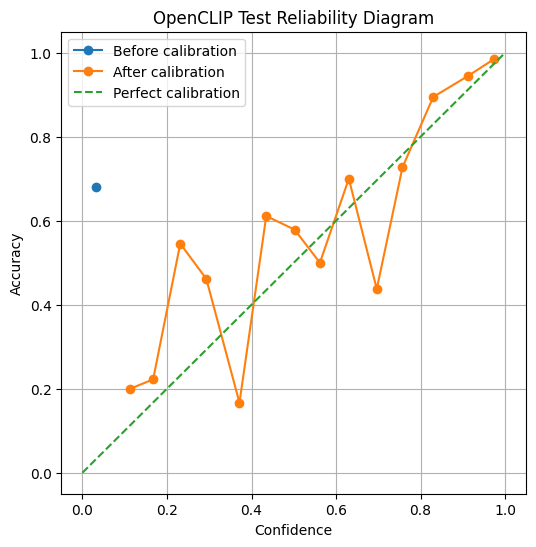

In [74]:
# Cell 69: Test calibration and reliability diagram

import matplotlib.pyplot as plt

def calculate_ece(confidence, correct, n_bins=15):
    bin_edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0

    for i in range(n_bins):
        in_bin = (
            (confidence > bin_edges[i]) &
            (confidence <= bin_edges[i + 1])
        )

        if in_bin.any():
            accuracy = correct[in_bin].mean()
            average_confidence = confidence[in_bin].mean()
            ece += in_bin.mean() * abs(
                accuracy - average_confidence
            )

    return ece

# Final test predictions and correctness
test_predictions_cal, test_correct_cal = get_top1_correctness(
    test_scores, test_true_labels
)

test_confidence_before = get_confidence(test_scores)
test_confidence_after = get_confidence(
    test_scores, best_temperature
)

ece_before = calculate_ece(
    test_confidence_before, test_correct_cal
)
ece_after = calculate_ece(
    test_confidence_after, test_correct_cal
)

print("Test accuracy:", round(test_correct_cal.mean(), 3))
print("Test ECE before:", round(ece_before, 4))
print("Test ECE after:", round(ece_after, 4))
print("Test mean confidence before:",
      round(test_confidence_before.mean(), 3))
print("Test mean confidence after:",
      round(test_confidence_after.mean(), 3))

# Reliability diagram
plt.figure(figsize=(6, 6))

for confidence, label in [
    (test_confidence_before, "Before calibration"),
    (test_confidence_after, "After calibration")
]:
    bin_edges = np.linspace(0, 1, 16)
    bin_accuracy = []
    bin_confidence = []

    for i in range(15):
        in_bin = (
            (confidence > bin_edges[i]) &
            (confidence <= bin_edges[i + 1])
        )

        if in_bin.any():
            bin_accuracy.append(test_correct_cal[in_bin].mean())
            bin_confidence.append(confidence[in_bin].mean())

    plt.plot(bin_confidence, bin_accuracy, marker="o", label=label)

plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
plt.xlabel("Confidence")
plt.ylabel("Accuracy")
plt.title("OpenCLIP Test Reliability Diagram")
plt.legend()
plt.grid(True)
plt.show()

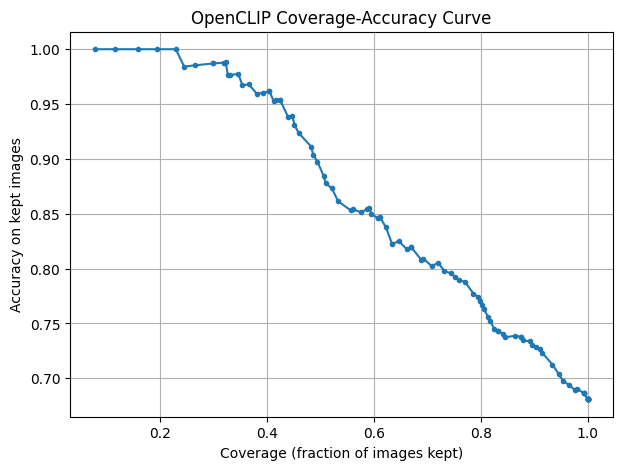

Coverage at 50% confidence: 0.669
Accuracy at 50% confidence: 0.82


In [75]:
# Cell 70: Coverage-accuracy curve

thresholds = np.linspace(0, 1, 101)

coverage_values = []
accuracy_values = []

for threshold in thresholds:
    selected = test_confidence_after >= threshold

    coverage_values.append(selected.mean())

    if selected.any():
        accuracy_values.append(test_correct_cal[selected].mean())
    else:
        accuracy_values.append(np.nan)

plt.figure(figsize=(7, 5))
plt.plot(coverage_values, accuracy_values, marker=".")
plt.xlabel("Coverage (fraction of images kept)")
plt.ylabel("Accuracy on kept images")
plt.title("OpenCLIP Coverage-Accuracy Curve")
plt.grid(True)
plt.show()

print("Coverage at 50% confidence:",
      round((test_confidence_after >= 0.50).mean(), 3))
print("Accuracy at 50% confidence:",
      round(test_correct_cal[test_confidence_after >= 0.50].mean(), 3)
      if (test_confidence_after >= 0.50).any() else "No images")

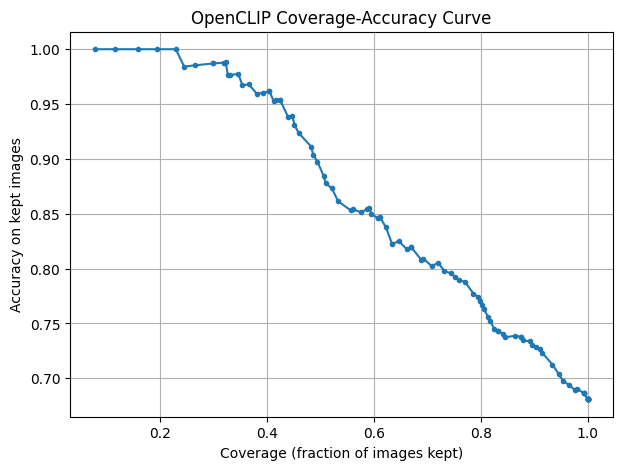

Saved calibration_results.csv
Saved coverage_accuracy_curve.png
Results folder: /content/ingen_vlm_bench_v1.0/results


In [76]:
# Cell 71: Save calibration results

import os
import pandas as pd
import matplotlib.pyplot as plt

results_folder = os.path.join(project_folder, "results")
os.makedirs(results_folder, exist_ok=True)

calibration_results = pd.DataFrame([{
    "model": "OpenCLIP ViT-B/32",
    "prompt": "prompt_ensemble",
    "temperature": best_temperature,
    "test_accuracy": test_correct_cal.mean(),
    "test_ece_before": ece_before,
    "test_ece_after": ece_after,
    "test_mean_confidence_before": test_confidence_before.mean(),
    "test_mean_confidence_after": test_confidence_after.mean(),
    "coverage_at_50_percent": (test_confidence_after >= 0.50).mean(),
    "accuracy_at_50_percent": test_correct_cal[
        test_confidence_after >= 0.50
    ].mean()
}])

calibration_results.to_csv(
    os.path.join(results_folder, "calibration_results.csv"),
    index=False
)

# Save coverage-accuracy curve
plt.figure(figsize=(7, 5))
plt.plot(coverage_values, accuracy_values, marker=".")
plt.xlabel("Coverage (fraction of images kept)")
plt.ylabel("Accuracy on kept images")
plt.title("OpenCLIP Coverage-Accuracy Curve")
plt.grid(True)

plt.savefig(
    os.path.join(results_folder, "coverage_accuracy_curve.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Saved calibration_results.csv")
print("Saved coverage_accuracy_curve.png")
print("Results folder:", results_folder)

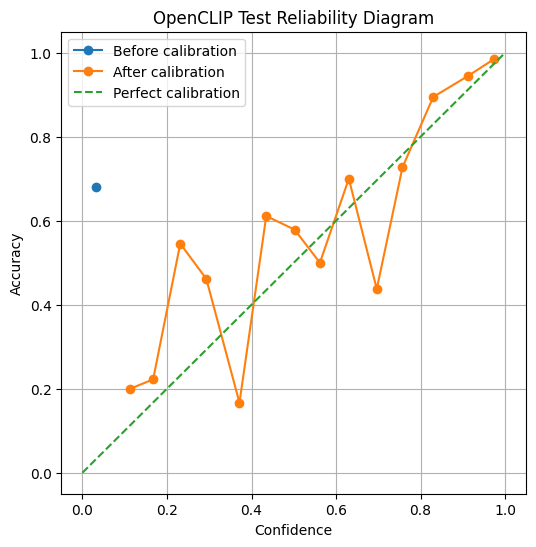

Saved reliability_diagram.png


In [77]:
# Cell 72: Save reliability diagram

plt.figure(figsize=(6, 6))

for confidence, label in [
    (test_confidence_before, "Before calibration"),
    (test_confidence_after, "After calibration")
]:
    bin_edges = np.linspace(0, 1, 16)
    bin_accuracy = []
    bin_confidence = []

    for i in range(15):
        in_bin = (
            (confidence > bin_edges[i]) &
            (confidence <= bin_edges[i + 1])
        )

        if in_bin.any():
            bin_accuracy.append(test_correct_cal[in_bin].mean())
            bin_confidence.append(confidence[in_bin].mean())

    plt.plot(bin_confidence, bin_accuracy, marker="o", label=label)

plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
plt.xlabel("Confidence")
plt.ylabel("Accuracy")
plt.title("OpenCLIP Test Reliability Diagram")
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(results_folder, "reliability_diagram.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Saved reliability_diagram.png")

In [78]:
# Cell 73: Save final test results table

final_results = pd.DataFrame([
    {
        "Model": "OpenCLIP ViT-B/32",
        "Selected configuration": "English prompt ensemble",
        "Top-1": 0.681,
        "Top-1 95% CI": "0.619–0.735",
        "Top-5": 0.918,
        "Top-5 95% CI": "0.887–0.949",
        "Macro-F1": 0.380,
        "Macro-F1 95% CI": "0.337–0.403"
    },
    {
        "Model": "Chinese-CLIP ViT-B/16",
        "Selected configuration": "Mandarin labels",
        "Top-1": 0.634,
        "Top-1 95% CI": "0.580–0.693",
        "Top-5": 0.887,
        "Top-5 95% CI": "0.848–0.926",
        "Macro-F1": 0.355,
        "Macro-F1 95% CI": "0.320–0.378"
    },
    {
        "Model": "SigLIP 2 base",
        "Selected configuration": "English prompts",
        "Top-1": 0.031,
        "Top-1 95% CI": "0.012–0.054",
        "Top-5": 0.171,
        "Top-5 95% CI": "0.128–0.218",
        "Macro-F1": 0.026,
        "Macro-F1 95% CI": "0.010–0.038"
    }
])

final_results.to_csv(
    os.path.join(results_folder, "final_test_results.csv"),
    index=False
)

display(final_results)

print("Saved final_test_results.csv")

,Model,Selected configuration,Top-1,Top-1 95% CI,Top-5,Top-5 95% CI,Macro-F1,Macro-F1 95% CI
0,OpenCLIP ViT-B/32,English prompt ensemble,0.681,0.619–0.735,0.918,0.887–0.949,0.380,0.337–0.403
1,Chinese-CLIP ViT-B/16,Mandarin labels,0.634,0.580–0.693,0.887,0.848–0.926,0.355,0.320–0.378
2,SigLIP 2 base,English prompts,0.031,0.012–0.054,0.171,0.128–0.218,0.026,0.010–0.038


Saved final_test_results.csv


In [79]:
# Cell 74: Check saved result files

print("Files saved in results folder:\n")

for filename in sorted(os.listdir(results_folder)):
    print(filename)

Files saved in results folder:

calibration_results.csv
coverage_accuracy_curve.png
final_test_results.csv
model_comparison_validation.csv
per_class_validation.csv
register.csv
reliability_diagram.png


,Slice,Category,Images,Accuracy
0,lighting,unknown,260,0.680769
1,clutter,unknown,260,0.680769
2,viewpoint,unknown,260,0.680769


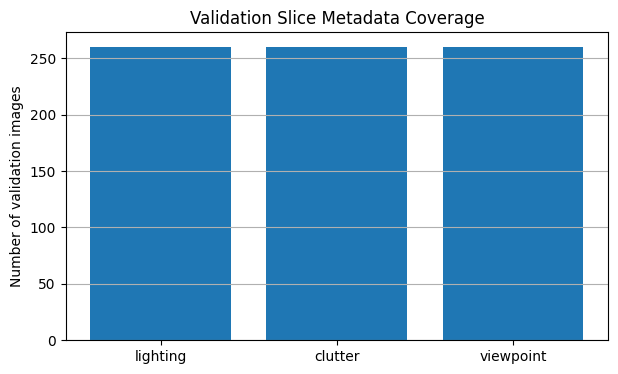

Saved slice_metadata_coverage.png


In [80]:
# Cell 75: Show the available validation slice information

slice_columns = ["lighting", "clutter", "viewpoint"]

slice_summary = []

for column in slice_columns:
    counts = val_rows[column].fillna("unknown").value_counts()

    for category, count in counts.items():
        slice_summary.append({
            "Slice": column,
            "Category": category,
            "Images": count,
            "Accuracy": val_correct.mean()
        })

slice_summary_df = pd.DataFrame(slice_summary)

display(slice_summary_df)

plt.figure(figsize=(7, 4))
plt.bar(
    slice_summary_df["Slice"],
    slice_summary_df["Images"]
)
plt.ylabel("Number of validation images")
plt.title("Validation Slice Metadata Coverage")
plt.grid(axis="y")

plt.savefig(
    os.path.join(results_folder, "slice_metadata_coverage.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Saved slice_metadata_coverage.png")

In [81]:
# Cell 76: Test evaluation with 10 known examples

fixture_scores = np.zeros((10, len(english_labels)))
fixture_labels = []

# Use 10 known labels from the taxonomy
for i in range(10):
    true_label = english_labels[i]
    fixture_labels.append({true_label})

    # Put the correct label in the top 5 for every image
    fixture_scores[i, i] = 0.9

    # For images 8 and 9, make another label rank first
    if i in [8, 9]:
        wrong_label = (i + 10) % len(english_labels)
        fixture_scores[i, wrong_label] = 1.0

# Check predictions
fixture_top1 = fixture_scores.argmax(axis=1)

fixture_top5 = np.argsort(
    fixture_scores, axis=1
)[:, -5:]

fixture_top1_correct = np.array([
    english_labels[pred] in labels
    for pred, labels in zip(fixture_top1, fixture_labels)
])

fixture_top5_correct = np.array([
    any(english_labels[pred] in labels for pred in top5)
    for top5, labels in zip(fixture_top5, fixture_labels)
])

print("Fixture images:", len(fixture_labels))
print("Top-1 accuracy:", fixture_top1_correct.mean())
print("Top-5 accuracy:", fixture_top5_correct.mean())

assert len(fixture_labels) == 10
assert fixture_top1_correct.mean() == 0.8
assert fixture_top5_correct.mean() == 1.0

print("10-image unit test passed!")

Fixture images: 10
Top-1 accuracy: 0.8
Top-5 accuracy: 1.0
10-image unit test passed!


In [82]:
# Cell 77: Per-class test accuracy and 95% CI

per_class_test_results = []

test_predictions = test_scores.argmax(axis=1)

for class_name in english_labels:
    # Images whose ground truth includes this class
    class_indices = [
        i for i, labels in enumerate(test_true_labels)
        if class_name in labels
    ]

    if len(class_indices) == 0:
        continue

    correct = np.array([
        english_labels[test_predictions[i]] in test_true_labels[i]
        for i in class_indices
    ], dtype=float)

    accuracy = correct.mean()

    # Bootstrap 95% confidence interval
    boot_accuracies = []

    for _ in range(1000):
        sample = rng.choice(
            correct,
            size=len(correct),
            replace=True
        )
        boot_accuracies.append(sample.mean())

    ci_low, ci_high = np.percentile(
        boot_accuracies, [2.5, 97.5]
    )

    per_class_test_results.append({
        "Class": class_name,
        "Images": len(class_indices),
        "Top-1 Accuracy": accuracy,
        "95% CI Lower": ci_low,
        "95% CI Upper": ci_high
    })

per_class_test_df = pd.DataFrame(per_class_test_results)

per_class_test_df = per_class_test_df.sort_values(
    "Top-1 Accuracy"
)

per_class_test_df.to_csv(
    os.path.join(results_folder, "per_class_test_results.csv"),
    index=False
)

display(per_class_test_df)

print("Saved per_class_test_results.csv")

,Class,Images,Top-1 Accuracy,95% CI Lower,95% CI Upper
20,Window,17,0.352941,0.117647,0.588235
13,Chair,16,0.437500,0.187500,0.687500
0,Glasses,14,0.500000,0.214286,0.785714
8,Bowl,15,0.533333,0.266667,0.800000
10,Spoon,13,0.538462,0.230769,0.769231
16,Desk,11,0.545455,0.272727,0.818182
11,Fork,18,0.611111,0.388889,0.833333
17,Door,13,0.615385,0.384615,0.846154
1,Remote control,3,0.666667,0.000000,1.000000
4,Book,19,0.684211,0.473684,0.894737


Saved per_class_test_results.csv


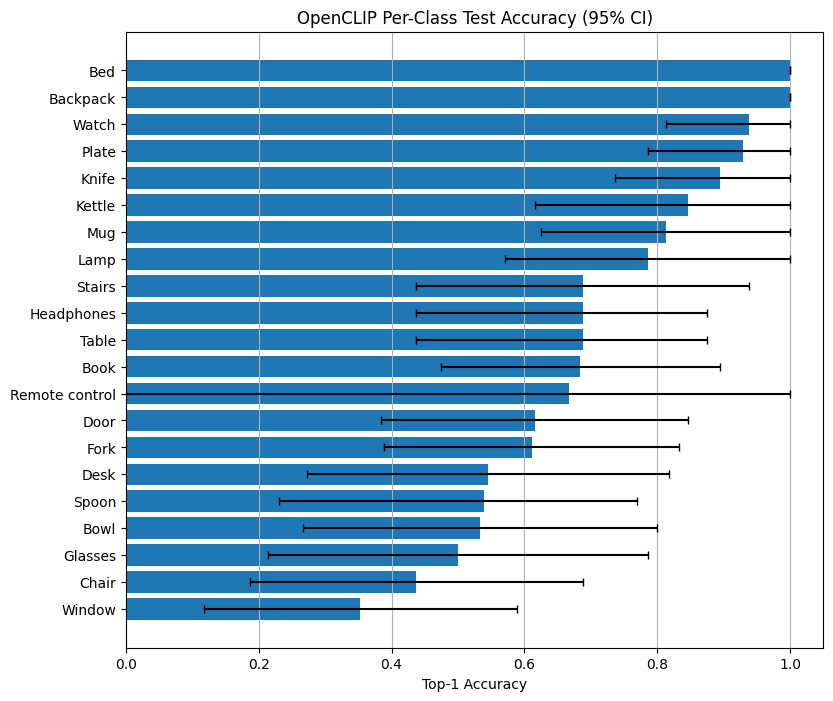

Saved per_class_test_accuracy.png


In [83]:
# Cell 78: Per-class test accuracy chart with confidence intervals

plot_df = per_class_test_df.sort_values("Top-1 Accuracy")

lower_error = (
    plot_df["Top-1 Accuracy"] - plot_df["95% CI Lower"]
)
upper_error = (
    plot_df["95% CI Upper"] - plot_df["Top-1 Accuracy"]
)

plt.figure(figsize=(9, 8))

plt.barh(
    plot_df["Class"],
    plot_df["Top-1 Accuracy"],
    xerr=[lower_error, upper_error],
    capsize=3
)

plt.xlabel("Top-1 Accuracy")
plt.title("OpenCLIP Per-Class Test Accuracy (95% CI)")
plt.xlim(0, 1.05)
plt.grid(axis="x")

plt.savefig(
    os.path.join(results_folder, "per_class_test_accuracy.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved per_class_test_accuracy.png")

In [84]:
# Cell 79: Save final OpenCLIP test predictions

test_prediction_rows = []

for i in range(len(test_rows)):
    top5 = np.argsort(test_scores[i])[-5:][::-1]
    top1 = top5[0]

    test_prediction_rows.append({
        "image_id": test_rows.loc[i, "image_id"],
        "image_path": test_paths[i],
        "ground_truth": ";".join(sorted(test_true_labels[i])),
        "top1_prediction": english_labels[top1],
        "top5_predictions": ";".join(
            english_labels[index] for index in top5
        ),
        "confidence_before_calibration": test_confidence_before[i],
        "confidence_after_calibration": test_confidence_after[i],
        "top1_correct": test_correct_cal[i]
    })

test_predictions_df = pd.DataFrame(test_prediction_rows)

test_predictions_df.to_csv(
    os.path.join(results_folder, "openclip_test_predictions.csv"),
    index=False
)

print("Saved openclip_test_predictions.csv")
print("Prediction rows:", len(test_predictions_df))
display(test_predictions_df.head())

Saved openclip_test_predictions.csv
Prediction rows: 257


,image_id,image_path,ground_truth,top1_prediction,top5_predictions,confidence_before_calibration,confidence_after_calibration,top1_correct
0,003775320f1d6937,/content/ingen_vlm_bench_v1.0/data/images/open...,Table,Table,Table;Cabinet;Object on floor;Bowl;Plate,0.030264,0.638679,1.0
1,00eb69293aa4c5b7,/content/ingen_vlm_bench_v1.0/data/images/open...,Glasses,Glasses,Glasses;Spoon;Headphones;Lamp;Chair,0.031295,0.936472,1.0
2,00f3dbbbf5bdf2cf,/content/ingen_vlm_bench_v1.0/data/images/open...,Window,Table,Table;Sofa;Chair;Bed;Food container,0.029287,0.224376,0.0
3,02d3d8579d152a67,/content/ingen_vlm_bench_v1.0/data/images/open...,Chair,Chair,Chair;Desk;Table;Cabinet;Open cabinet,0.030284,0.481407,1.0
4,02d46139315081c5,/content/ingen_vlm_bench_v1.0/data/images/open...,Spoon,Spoon,Spoon;Fork;Fallen object;Knife;Object on floor,0.032778,0.973001,1.0


In [85]:
# Cell 80: Final benchmark summary

print("WEEK 4 ZERO-SHOT BENCHMARK SUMMARY")
print("=" * 40)

print("\nSelected validation configurations:")
print("- OpenCLIP: English prompt ensemble")
print("- Chinese-CLIP: Mandarin labels")
print("- SigLIP 2: English prompts")

print("\nFinal test results:")
display(final_results)

print("\nCalibration:")
print("Temperature:", round(best_temperature, 4))
print("Test ECE before:", round(ece_before, 4))
print("Test ECE after:", round(ece_after, 4))
print("Coverage at 50% confidence:",
      round((test_confidence_after >= 0.50).mean(), 3))
print("Accuracy at 50% confidence:",
      round(test_correct_cal[test_confidence_after >= 0.50].mean(), 3))

print("\nUnit test: PASSED")
print("Test images evaluated:", len(test_rows))
print("Missing test images:", sum(not os.path.exists(p) for p in test_paths))

print("\nResults files:")
for filename in sorted(os.listdir(results_folder)):
    print("-", filename)

WEEK 4 ZERO-SHOT BENCHMARK SUMMARY

Selected validation configurations:
- OpenCLIP: English prompt ensemble
- Chinese-CLIP: Mandarin labels
- SigLIP 2: English prompts

Final test results:


,Model,Selected configuration,Top-1,Top-1 95% CI,Top-5,Top-5 95% CI,Macro-F1,Macro-F1 95% CI
0,OpenCLIP ViT-B/32,English prompt ensemble,0.681,0.619–0.735,0.918,0.887–0.949,0.380,0.337–0.403
1,Chinese-CLIP ViT-B/16,Mandarin labels,0.634,0.580–0.693,0.887,0.848–0.926,0.355,0.320–0.378
2,SigLIP 2 base,English prompts,0.031,0.012–0.054,0.171,0.128–0.218,0.026,0.010–0.038



Calibration:
Temperature: 0.0181
Test ECE before: 0.6498
Test ECE after: 0.0903
Coverage at 50% confidence: 0.669
Accuracy at 50% confidence: 0.82

Unit test: PASSED
Test images evaluated: 257
Missing test images: 0

Results files:
- calibration_results.csv
- coverage_accuracy_curve.png
- final_test_results.csv
- model_comparison_validation.csv
- openclip_test_predictions.csv
- per_class_test_accuracy.png
- per_class_test_results.csv
- per_class_validation.csv
- register.csv
- reliability_diagram.png
- slice_metadata_coverage.png


In [86]:
# Cell 81: Save validation prompt ablation results

prompt_ablation_results = pd.DataFrame([
    {
        "Prompt setting": "Bare label",
        "Top-1": 0.596,
        "Top-1 95% CI": "0.538–0.654",
        "Top-5": 0.785,
        "Top-5 95% CI": "0.731–0.831",
        "Macro-F1": 0.328,
        "Macro-F1 95% CI": "0.287–0.352"
    },
    {
        "Prompt setting": "A photo of a {label}",
        "Top-1": 0.677,
        "Top-1 95% CI": "0.623–0.731",
        "Top-5": 0.908,
        "Top-5 95% CI": "0.869–0.942",
        "Macro-F1": 0.387,
        "Macro-F1 95% CI": "0.343–0.414"
    },
    {
        "Prompt setting": "10-template ensemble",
        "Top-1": 0.681,
        "Top-1 95% CI": "0.627–0.738",
        "Top-5": 0.888,
        "Top-5 95% CI": "0.850–0.923",
        "Macro-F1": 0.389,
        "Macro-F1 95% CI": "0.346–0.415"
    }
])

prompt_ablation_results.to_csv(
    os.path.join(results_folder, "prompt_ablation_validation.csv"),
    index=False
)

display(prompt_ablation_results)

print("Saved prompt_ablation_validation.csv")

,Prompt setting,Top-1,Top-1 95% CI,Top-5,Top-5 95% CI,Macro-F1,Macro-F1 95% CI
0,Bare label,0.596,0.538–0.654,0.785,0.731–0.831,0.328,0.287–0.352
1,A photo of a {label},0.677,0.623–0.731,0.908,0.869–0.942,0.387,0.343–0.414
2,10-template ensemble,0.681,0.627–0.738,0.888,0.850–0.923,0.389,0.346–0.415


Saved prompt_ablation_validation.csv


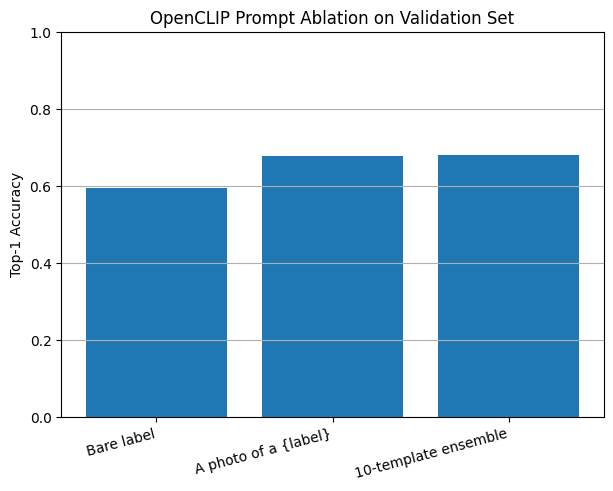

Saved prompt_ablation_validation.png


In [87]:
# Cell 82: Plot prompt ablation results

plt.figure(figsize=(7, 5))

plt.bar(
    prompt_ablation_results["Prompt setting"],
    prompt_ablation_results["Top-1"]
)

plt.ylabel("Top-1 Accuracy")
plt.title("OpenCLIP Prompt Ablation on Validation Set")
plt.ylim(0, 1)
plt.grid(axis="y")
plt.xticks(rotation=15, ha="right")

plt.savefig(
    os.path.join(results_folder, "prompt_ablation_validation.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved prompt_ablation_validation.png")

### How Zero-Shot Classification Works

Zero-shot classification compares an image with text descriptions of possible classes without training the model on the benchmark labels.

The image encoder converts an image into an embedding, and the text encoder converts each class prompt into an embedding. Both embeddings are L2-normalized, so their lengths become 1.

The model calculates the dot product between the normalized image embedding and each normalized text embedding. This is equivalent to cosine similarity. The class with the highest similarity score is the predicted label.

For prompt ensembling, the model encodes multiple descriptions of each class, averages their embeddings, and normalizes the result. This helps represent a class using more than one wording.

The benchmark evaluates the ranked class scores using Top-1 accuracy, Top-5 accuracy, and Macro-F1.